# Lab 2 — Sentinel distributions, LSB replacement and compressive sensing

Urban–natural pair: **Kraków** and **Puszcza Białowieska**.

The completed analysis includes verified inputs, normalized Sentinel-2 and Sentinel-1 histograms, reproducible two-LSB replacement, and the optional compressive-sensing exercise with convergence diagnostics, a corrected comparison and written EO observations. Section 5 verifies the saved results and their portability. See [SUBMISSION_REVIEW.md](SUBMISSION_REVIEW.md) for the assignment coverage and ZIP instructions. The original `Basic_opt.ipynb` is retained unchanged as the source tutorial.

In [1]:
from pathlib import Path
import sys
import json
import platform
from importlib.metadata import version

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'lab2/inputs.py').exists())
sys.path.insert(0, str(ROOT / 'lab2'))
import inputs as lab_inputs
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from PIL import Image

RANDOM_SEED = 20261109
print('Repository:', ROOT)
print('Python:', platform.python_version())
print({name: version(name) for name in ['numpy', 'rasterio', 'matplotlib', 'nbformat', 'nbclient', 'pyproj', 'pillow']})

Repository: /Users/molczane/Developer/MLForSpace
Python: 3.12.15
{'numpy': '2.5.4', 'rasterio': '1.5.2', 'matplotlib': '3.11.2', 'nbformat': '5.11.1', 'nbclient': '0.11.0', 'pyproj': '3.8.0', 'pillow': '13.0.0'}


## 1. Prepare the analysis notebook and inputs

Reuse the original lab 1 **surface-reflectance and integer DN GeoTIFFs**, rather than display RGB values, for the three optical bands. The helper verifies lab 1 hashes, checks DN-to-reflectance scale/offset and band order, and constructs a common valid-pixel mask.

For SAR, use Planetary Computer **Sentinel-1 RTC**, derived from GRD by Catalyst. Select the nearest acquisition within ±12 days with VV and VH and complete positive, finite coverage. The source is calibrated intensity with terrain normalization and UTM orthorectification. Store **gamma0 linear** and **10 log10(gamma0)** dB; do not treat these units as optical reflectance.

`prepare()` reuses and verifies saved inputs without network requests. If absent, it searches the catalogue and reads small COG windows. Use `prepare(refresh=True)` only when intentionally reacquiring. Download tokens remain in memory and are not saved. See [README](README.md) for access conditions and source links.

In [2]:
manifest = lab_inputs.prepare()
manifest, datasets = lab_inputs.load_inputs()
for key, record in manifest['regions'].items():
    optical, sar = record['sentinel2'], record['sentinel1']
    print(record['name'], '|', record['terrain'])
    print('  S2:', optical['scene_id'], optical['bands'], optical['acquired_utc'])
    print('  S1:', sar['scene_id'], sar['polarizations'], sar['acquired_utc'])
    print('  SAR minus optical time (hours):', round(sar['offset_from_sentinel2_hours'], 2))
    print('  Grid:', optical['shape'], optical['crs'], optical['pixel_spacing_m'], 'm')
    print('  Valid pixels: optical', optical['valid_pixels'], '| SAR', sar['valid_pixels'])
    print('  Linear gamma0 ranges:', sar['linear_ranges'])

Verified saved lab 2 inputs offline
Kraków | urban
  S2: S2A_T34UDA_20250813T094043_L2A ['B04', 'B03', 'B02'] 2025-08-13T09:46:56.167000Z
  S1: S1A_IW_GRDH_1SDV_20250812T045328_20250812T045353_060498_rtc ['VV', 'VH'] 2025-08-12T04:53:40.510232Z
  SAR minus optical time (hours): -28.89
  Grid: [512, 512] EPSG:32634 [10.0, 10.0] m
  Valid pixels: optical 262064 | SAR 262144
  Linear gamma0 ranges: {'VV': [0.0029979688115417957, 655.9075927734375], 'VH': [0.000868091534357518, 234.76268005371094]}
Puszcza Białowieska | forest
  S2: S2C_T34UFD_20250702T094053_L2A ['B04', 'B03', 'B02'] 2025-07-02T09:46:14.474000Z
  S1: S1A_IW_GRDH_1SDV_20250702T044406_20250702T044431_059900_0770BD_rtc ['VV', 'VH'] 2025-07-02T04:44:19.484596Z
  SAR minus optical time (hours): -5.03
  Grid: [512, 512] EPSG:32634 [10.0, 10.0] m
  Valid pixels: optical 262144 | SAR 262144
  Linear gamma0 ranges: {'VV': [0.006751593668013811, 0.8613353371620178], 'VH': [0.002924056025221944, 0.22538445889949799]}


### Masks, grids and interpretation

- Optical analysis uses a common mask across B04/B03/B02: finite, unmasked values, positive source DN, excluding SCL 0, 1, 3, 7, 8, 9, 10 and 11 (nodata/defective/cloud shadow/unclassified/cloud/cirrus/snow). SCL originated at 20 m and was nearest-neighbour sampled to 10 m in lab 1. Negative valid reflectance is retained. SCL 2 (dark/topographic-shadow areas) is retained and may affect distributions. The mask removes 80 Kraków pixels and no Białowieża pixels.
- SAR analysis uses finite, positive VV and VH jointly. It does not apply an optical cloud mask: radar is not screened by optical cloud classification. No additional speckle filtering, radiometric clipping or outlier removal is performed. The source nodata mask is respected; no separate layover/shadow product was available here, so positive finite coverage does not certify freedom from SAR geometry effects.
- Source SAR windows are sampled with nearest neighbour to the exact S2 CRS, transform and extent. Both output grids have 10 m pixel spacing, which is not the same as independent 10 m spatial resolution (the source GRD metadata describes approximately 20 × 22 m resolution). See the manifest for original source transforms and any CRS changes.
- Kraków is a mixed crop with buildings, vegetation and water, not a pure urban class. Białowieża is vegetation-dominated forest with natural variation and a small river corridor. These are representative footprints, not administrative boundaries. Different dates, viewing geometries and sensor physics confound a terrain-only comparison.
- Histograms below use sensor-specific masks; a pixelwise cross-sensor experiment would additionally require their intersection and consideration of registration accuracy. Numeric grid agreement alone does not establish perfect physical co-registration.

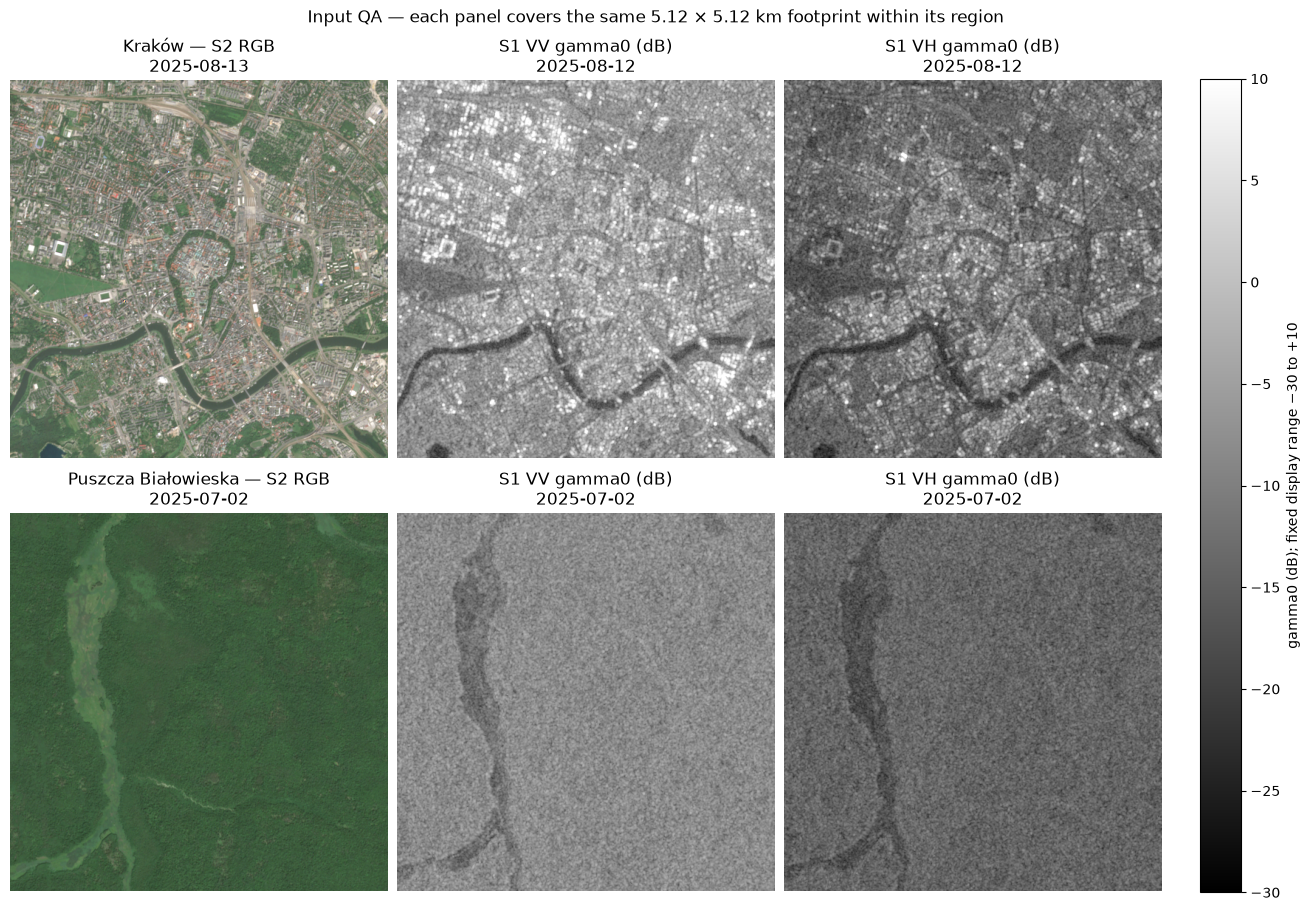

RGB display uses lab 1 fixed mapping: reflectance / 0.3, clipped, gamma 1/2.2, uint8.
SAR display clips at −30 and +10 dB only for visualization; full values remain in GeoTIFFs.


In [3]:
fig, axes = plt.subplots(2, 3, figsize=(13, 9), constrained_layout=True)
for row, (key, record) in enumerate(manifest['regions'].items()):
    values = datasets[key]
    with Image.open(ROOT / record['sentinel2']['paths']['preview']) as image:
        axes[row, 0].imshow(np.asarray(image))
    axes[row, 0].set_title(record['name'] + ' — S2 RGB\n' + record['sentinel2']['acquired_utc'][:10])
    for column, pol in enumerate(['VV', 'VH'], start=1):
        data = np.ma.array(values['sentinel1_db'][column - 1], mask=~values['sentinel1_mask'])
        display = axes[row, column].imshow(data, cmap='gray', vmin=-30, vmax=10)
        axes[row, column].set_title('S1 ' + pol + ' gamma0 (dB)\n' + record['sentinel1']['acquired_utc'][:10])
    for ax in axes[row]:
        ax.set_axis_off()
fig.colorbar(display, ax=axes[:, 1:].ravel().tolist(), label='gamma0 (dB); fixed display range −30 to +10')
fig.suptitle('Input QA — each panel covers the same 5.12 × 5.12 km footprint within its region')
preview_path = ROOT / 'lab2/data/input_comparison.png'
fig.savefig(preview_path, dpi=140)
plt.show()
print('RGB display uses lab 1 fixed mapping: reflectance / 0.3, clipped, gamma 1/2.2, uint8.')
print('SAR display clips at −30 and +10 dB only for visualization; full values remain in GeoTIFFs.')

In [4]:
verification = {'python': platform.python_version(), 'packages': {name: version(name) for name in ['numpy', 'rasterio', 'matplotlib', 'nbformat', 'nbclient', 'pyproj', 'pillow']}, 'regions': {}}
for key, values in datasets.items():
    s2, s1 = values['sentinel2_reflectance'], values['sentinel1_linear']
    assert s2.shape == (3, 512, 512) and s1.shape == (2, 512, 512)
    assert values['sentinel2_dn'].dtype == np.uint16
    assert s2.dtype == s1.dtype == np.float32
    assert values['sentinel2_mask'].dtype == values['sentinel1_mask'].dtype == bool
    for sensor in ['sentinel2', 'sentinel1']:
        assert int(values[sensor + '_mask'].sum()) == manifest['regions'][key][sensor]['valid_pixels']
    verification['regions'][key] = {'sentinel2_shape': list(s2.shape), 'sentinel1_shape': list(s1.shape), 's2_valid_pixels': int(values['sentinel2_mask'].sum()), 's1_valid_pixels': int(values['sentinel1_mask'].sum()), 'grid_and_hash_checks': 'passed'}
lab_inputs.dump(ROOT / 'lab2/data/verification.json', verification)
print('Passed: input hashes, all raster grids, band counts, dtypes, masks and dB conversion.')

Passed: input hashes, all raster grids, band counts, dtypes, masks and dB conversion.


### Provenance and source documentation

Full scene identifiers, source asset URLs (unsigned), calibration conversions, crop footprints, band order, acquisition times, time offsets, output paths, source grids and SHA-256 hashes are in [data/manifest.json](data/manifest.json). Saved source STAC items and candidate lists allow scene selection to be reviewed. Optical data are reused from `../lab1/data/sentinel2/`; SAR and masks are stored under `data/`.

- [Planetary Computer Sentinel-1 RTC collection and processing methodology](https://planetarycomputer.microsoft.com/api/stac/v1/collections/sentinel-1-rtc): calibrated gamma intensity, terrain correction with PlanetDEM and UTM orthorectification. Its documentation states an account is required; the public signing endpoint succeeded without credentials during this preparation. Future access may require an account; saved-crop analysis is offline.
- [Element 84 Earth Search Sentinel-2 Collection 1](https://earth-search.aws.element84.com/v1/collections/sentinel-2-c1-l2a) and [lab 1 acquisition notes](../lab1/README.md).

Contains modified Copernicus Sentinel data 2025. Sentinel-1 processed by Catalyst, hosted by Microsoft Planetary Computer (CC BY 4.0); Sentinel-2 accessed through Element 84 Earth Search.

## 2. Probability distributions / histograms — question 1

The labelled RGB, VV and VH previews in section 1 show the analysed footprints. The histograms below use **all valid band values**, not display intensities. Kraków has 262,064 valid optical pixels per band; Białowieża has 262,144. Both SAR crops have 262,144 valid pixels per polarization. The masks are sensor-specific and are described above.

For each bin, density = count / (N × bin width). Thus **sum(density × width) = 1**, while the bar heights themselves need not sum to one. These are empirical histogram estimates of the marginal probability density, without a fitted distribution or kernel smoothing. Checks below require every valid sample to be counted and every integral to equal one within floating-point tolerance.

Common bin edges are used across both regions and all bands within each representation: optical reflectance (width 0.005), SAR dB (width 0.5 dB), and an additional linear SAR view (80 logarithmically spaced bins). Every range covers the global minimum through maximum of that representation. Full-range plots use shared axes within each figure, without clipping samples. Linear SAR uses log x and log y axes to make the large dynamic range readable; density is still per unit **linear gamma0**, accounting for unequal bin widths. Zero-density bins are invisible on log y axes. The dB transform changes density shape; it is not just an axis relabelling.

Tables report population standard deviation and moment skewness, and the 5th/95th percentiles. Pixels are spatially correlated, so these describe these crops and are not independent replicate observations or confidence intervals. Numeric tables and bin counts are saved under `results/histograms/`.

In [5]:
import csv
from IPython.display import HTML, display

HIST_DIR = ROOT / 'lab2/results/histograms'
HIST_DIR.mkdir(parents=True, exist_ok=True)
region_names = {key: record['name'] for key, record in manifest['regions'].items()}
representations = {
    's2_reflectance': ('sentinel2_reflectance', 'sentinel2_mask', ['B04 red', 'B03 green', 'B02 blue'], 'BOA reflectance (dimensionless)'),
    's1_db': ('sentinel1_db', 'sentinel1_mask', ['VV', 'VH'], 'gamma0 (dB)'),
    's1_linear': ('sentinel1_linear', 'sentinel1_mask', ['VV', 'VH'], 'gamma0 (linear intensity ratio)'),
}
samples, edges, histogram_data, summary_rows = {}, {}, {}, []
for representation, (data_key, mask_key, bands, units) in representations.items():
    samples[representation] = {
        (region, band): values[data_key][i][values[mask_key]].astype(np.float64)
        for region, values in datasets.items() for i, band in enumerate(bands)
    }
    minimum = min(x.min() for x in samples[representation].values())
    maximum = max(x.max() for x in samples[representation].values())
    if representation == 's1_linear':
        edges[representation] = np.geomspace(minimum, maximum, 81)
    else:
        width = 0.005 if representation == 's2_reflectance' else 0.5
        low = np.floor(minimum / width) * width
        high = np.ceil(maximum / width) * width
        edges[representation] = np.linspace(low, high, int(round((high - low) / width)) + 1)
    bin_edges = edges[representation]
    histogram_data[representation] = {}
    for (region, band), x in samples[representation].items():
        assert x.size and np.isfinite(x).all()
        counts, _ = np.histogram(x, bins=bin_edges)
        density = counts / (x.size * np.diff(bin_edges))
        integral = float(np.sum(density * np.diff(bin_edges)))
        assert int(counts.sum()) == x.size, 'Histogram omitted valid samples'
        np.testing.assert_allclose(integral, 1.0, rtol=0, atol=1e-12)
        histogram_data[representation][(region, band)] = (counts, density)
        mean, std = float(x.mean()), float(x.std())
        q05, median, q95 = np.quantile(x, [0.05, 0.5, 0.95])
        mode_bin = int(np.argmax(density))
        summary_rows.append({
            'representation': representation, 'region': region, 'band': band, 'units': units,
            'n': x.size, 'min': float(x.min()), 'p05': float(q05), 'median': float(median),
            'mean': mean, 'p95': float(q95), 'max': float(x.max()), 'std': std,
            'skewness': float(np.mean(((x - mean) / std) ** 3)) if std else 0.0,
            'modal_bin_left': float(bin_edges[mode_bin]), 'modal_bin_right': float(bin_edges[mode_bin + 1]),
            'density_integral': integral,
        })
        filename = representation + '_' + region + '_' + band.split()[0] + '.csv'
        with (HIST_DIR / filename).open('w', newline='') as handle:
            writer = csv.writer(handle)
            writer.writerow(['bin_left', 'bin_right', 'count', 'density'])
            writer.writerows(zip(bin_edges[:-1], bin_edges[1:], counts, density))
with (HIST_DIR / 'summary.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(summary_rows[0]))
    writer.writeheader()
    writer.writerows(summary_rows)
lab_inputs.dump(HIST_DIR / 'run_metadata.json', {
    'source_sha256': manifest['sha256'], 'versions': verification['packages'],
    'bins': {key: value.tolist() for key, value in edges.items()},
    'density_definition': 'count / (valid N * bin width); no radiometric clipping',
    'normalization_tolerance': 1e-12, 'distributions_checked': len(summary_rows),
})
def show_summary(representation):
    columns = ['region', 'band', 'n', 'min', 'p05', 'median', 'mean', 'p95', 'max', 'std', 'skewness']
    selected = [row for row in summary_rows if row['representation'] == representation]
    header = '<tr>' + ''.join('<th>' + key + '</th>' for key in columns) + '</tr>'
    body = ''.join('<tr>' + ''.join('<td>' + (format(row[key], '.5g') if isinstance(row[key], float) else str(row[key])) + '</td>' for key in columns) + '</tr>' for row in selected)
    display(HTML('<table>' + header + body + '</table>'))
print('Passed count coverage and density normalization for', len(summary_rows), 'distributions.')
show_summary('s2_reflectance')
show_summary('s1_db')
show_summary('s1_linear')

Passed count coverage and density normalization for 14 distributions.


region,band,n,min,p05,median,mean,p95,max,std,skewness
krakow,B04 red,262064,-0.0326,0.025,0.0697,0.077241,0.157,1.6248,0.045607,2.0662
krakow,B03 green,262064,-0.0149,0.0386,0.0723,0.079732,0.1442,0.8968,0.037026,2.5886
krakow,B02 blue,262064,-0.0996,0.0246,0.0546,0.062319,0.126,1.7816,0.037016,3.187
bialowieza,B04 red,262144,0.0043,0.0097,0.0132,0.014168,0.0237,0.0782,0.0044638,2.6164
bialowieza,B03 green,262144,0.0106,0.0234,0.0314,0.032691,0.0494,0.1144,0.0075236,1.5701
bialowieza,B02 blue,262144,0.0032,0.0094,0.013,0.013699,0.0222,0.0664,0.0036407,1.7721


region,band,n,min,p05,median,mean,p95,max,std,skewness
krakow,VV,262144,-25.232,-12.452,-5.8931,-5.3609,3.658,28.168,4.9754,0.65308
krakow,VH,262144,-30.614,-18.581,-12.733,-12.157,-3.9519,23.706,4.5132,0.77045
bialowieza,VV,262144,-21.706,-12.476,-8.3636,-8.5278,-5.1671,-0.64828,2.2354,-0.48879
bialowieza,VH,262144,-25.34,-18.017,-14.236,-14.353,-11.101,-6.4708,2.1059,-0.33501


region,band,n,min,p05,median,mean,p95,max,std,skewness
krakow,VV,262144,0.002998,0.056857,0.25745,0.74976,2.3217,655.91,3.66,71.922
krakow,VH,262144,0.00086809,0.013865,0.053302,0.14014,0.40254,234.76,1.1634,110
bialowieza,VV,262144,0.0067516,0.056541,0.14576,0.1587,0.30429,0.86134,0.078058,1.1254
bialowieza,VH,262144,0.0029241,0.015787,0.037709,0.041039,0.077614,0.22538,0.019521,1.1523


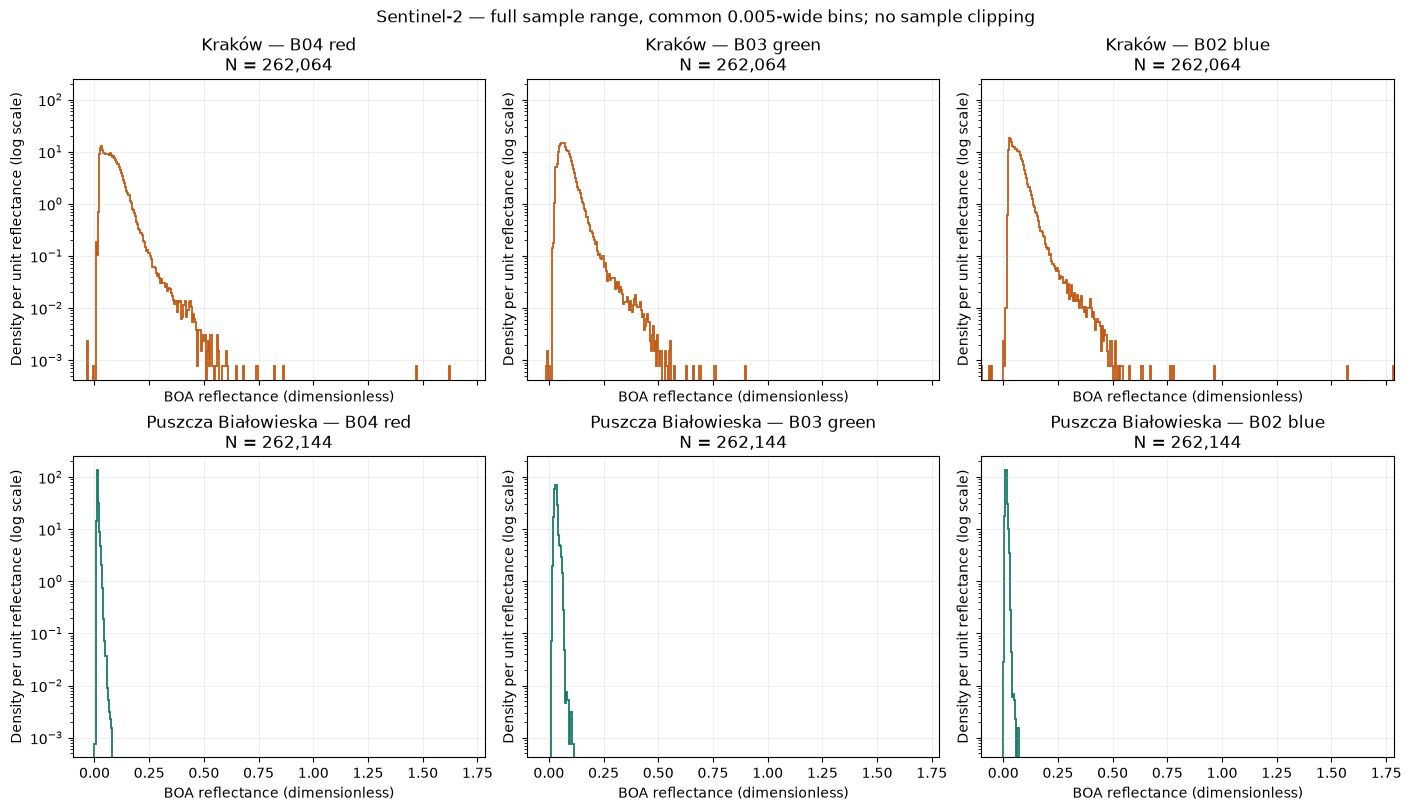

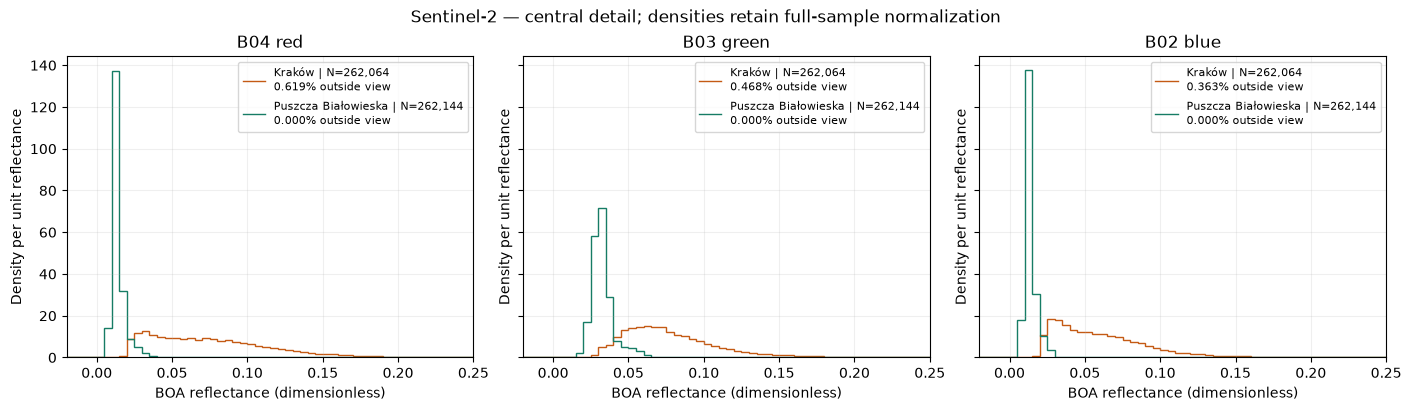

krakow B04 red modal bin: 0.03 to 0.035 | below 0: 4 | above 1: 2
krakow B03 green modal bin: 0.06 to 0.065 | below 0: 3 | above 1: 0
krakow B02 blue modal bin: 0.025 to 0.03 | below 0: 3 | above 1: 2
bialowieza B04 red modal bin: 0.01 to 0.015 | below 0: 0 | above 1: 0
bialowieza B03 green modal bin: 0.03 to 0.035 | below 0: 0 | above 1: 0
bialowieza B02 blue modal bin: 0.01 to 0.015 | below 0: 0 | above 1: 0


In [6]:
REGION_COLORS = {'krakow': '#c45a14', 'bialowieza': '#167c65'}
# Full-range overview: all six optical distributions; log density reveals rare tails.
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharex=True, sharey=True, constrained_layout=True)
for row, region in enumerate(datasets):
    for col, band in enumerate(representations['s2_reflectance'][2]):
        ax = axes[row, col]
        counts, density = histogram_data['s2_reflectance'][(region, band)]
        ax.stairs(density, edges['s2_reflectance'], color=REGION_COLORS[region], linewidth=1.3)
        ax.set_yscale('log')
        ax.set_xlim(edges['s2_reflectance'][[0, -1]])
        ax.set_title(region_names[region] + ' — ' + band + '\nN = ' + format(int(counts.sum()), ','))
        ax.set_xlabel('BOA reflectance (dimensionless)')
        ax.set_ylabel('Density per unit reflectance (log scale)')
        ax.grid(alpha=0.2)
fig.suptitle('Sentinel-2 — full sample range, common 0.005-wide bins; no sample clipping')
fig.savefig(HIST_DIR / 'sentinel2_full_range.png', dpi=150)
plt.show()

# Central view uses the SAME density (not a truncated/renormalized histogram).
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True, constrained_layout=True)
focus = (-0.02, 0.25)
for ax, band in zip(axes, representations['s2_reflectance'][2]):
    for region in datasets:
        x = samples['s2_reflectance'][(region, band)]
        _, density = histogram_data['s2_reflectance'][(region, band)]
        outside = 100 * np.mean((x < focus[0]) | (x > focus[1]))
        label = region_names[region] + ' | N=' + format(x.size, ',') + '\n' + format(outside, '.3f') + '% outside view'
        ax.stairs(density, edges['s2_reflectance'], label=label, color=REGION_COLORS[region])
    ax.set_xlim(focus)
    ax.set_title(band)
    ax.set_xlabel('BOA reflectance (dimensionless)')
    ax.set_ylabel('Density per unit reflectance')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('Sentinel-2 — central detail; densities retain full-sample normalization')
fig.savefig(HIST_DIR / 'sentinel2_central_detail.png', dpi=150)
plt.show()
for row in summary_rows:
    if row['representation'] == 's2_reflectance':
        x = samples['s2_reflectance'][(row['region'], row['band'])]
        print(row['region'], row['band'], 'modal bin:', round(row['modal_bin_left'], 4), 'to', round(row['modal_bin_right'], 4),
              '| below 0:', int((x < 0).sum()), '| above 1:', int((x > 1).sum()))

### Sentinel-2 observations

**Urban versus natural.** The forest distributions are concentrated at lower reflectance than Kraków in every band. Median red/green/blue reflectances are **0.0132 / 0.0314 / 0.0130** in Białowieża, versus **0.0697 / 0.0723 / 0.0546** in Kraków. The forest standard deviations are **0.00446 / 0.00752 / 0.00364**, compared with **0.04561 / 0.03703 / 0.03702** in the urban crop. The narrow forest peaks and broader urban curves agree with the visually more homogeneous forest canopy and Kraków's mixture of roofs, roads, vegetation and the Vistula. This is an interpretation of the crop composition, not proof that terrain alone caused the differences.

**Band differences and peaks.** In Białowieża, green has a higher median and wider spread than red or blue; its highest-density bin is **0.030–0.035**, whereas red and blue peak in **0.010–0.015**. This agrees with the green appearance of the RGB preview. Kraków's highest bins are **0.030–0.035 red**, **0.060–0.065 green**, and **0.025–0.030 blue**. Red shows a broad shoulder extending beyond its low-reflectance peak; green has a more distinct central hump. Red is the widest urban band by standard deviation. These peak intervals depend on the chosen 0.005 bin width and are not exact physical modes or evidence of distinct material classes.

**Tails and quality limits.** All six distributions have positive moment skewness, with means above medians; they are not symmetric bell curves. Skewness ranges from **2.07–3.19** in Kraków and **1.57–2.62** in Białowieża. Thus a narrow forest histogram can still be strongly right-skewed. Kraków has rare extreme values: 4 red, 3 green and 3 blue samples are negative; 2 red and 2 blue samples exceed 1 (these are band-sample counts, not necessarily distinct pixels). They pass the prepared mask and are preserved, not asserted to be physically reliable surface properties. Residual processing artefacts and bright-target effects would need a targeted investigation. The central view excludes from display only **0.619% / 0.468% / 0.363%** of Kraków's red/green/blue samples and none of the forest samples; all remain in the full histogram and summary statistics. The SCL mask is not a guarantee that every remaining value is artefact-free.

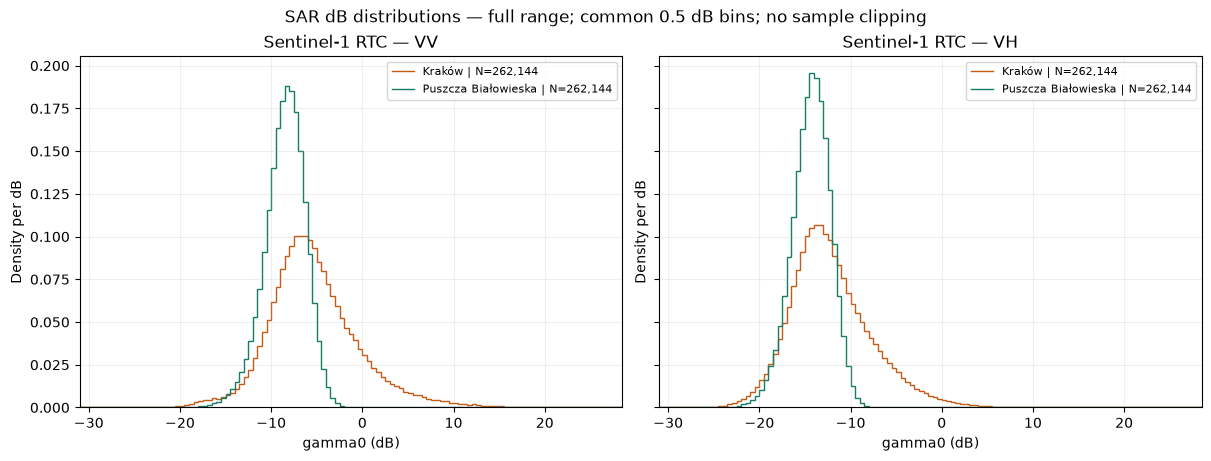

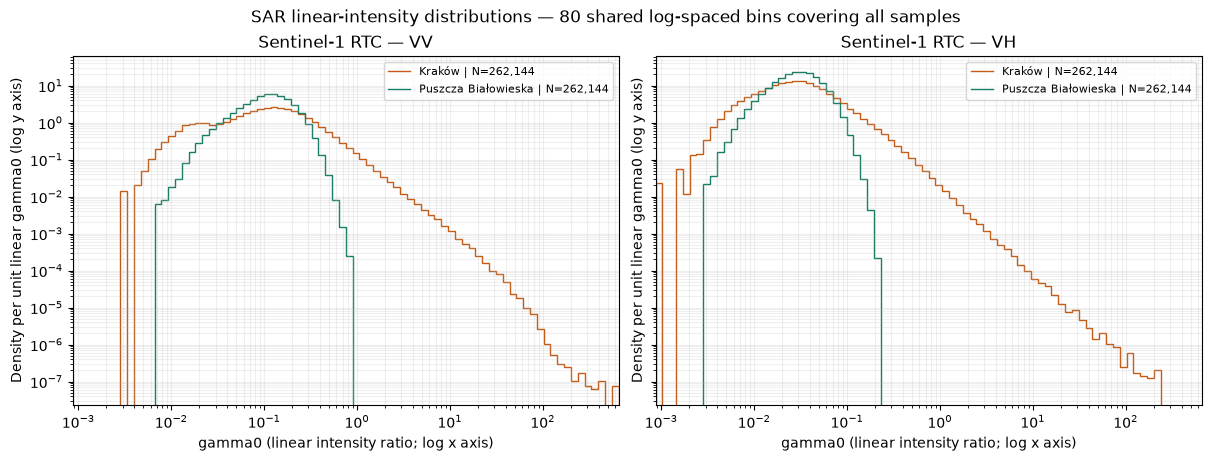

All plots use full-sample density normalization; central optical view only changes x limits.
Every histogram counts all valid samples; no trimming, smoothing, fitting or additional speckle filter.
krakow VV modal 0.5 dB bin: -7.5 to -7.0
krakow VH modal 0.5 dB bin: -13.5 to -13.0
bialowieza VV modal 0.5 dB bin: -8.5 to -8.0
bialowieza VH modal 0.5 dB bin: -14.5 to -14.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, pol in zip(axes, ['VV', 'VH']):
    for region in datasets:
        counts, density = histogram_data['s1_db'][(region, pol)]
        label = region_names[region] + ' | N=' + format(int(counts.sum()), ',')
        ax.stairs(density, edges['s1_db'], label=label, color=REGION_COLORS[region])
    ax.set_xlim(edges['s1_db'][[0, -1]])
    ax.set_title('Sentinel-1 RTC — ' + pol)
    ax.set_xlabel('gamma0 (dB)')
    ax.set_ylabel('Density per dB')
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle('SAR dB distributions — full range; common 0.5 dB bins; no sample clipping')
fig.savefig(HIST_DIR / 'sentinel1_db.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharex=True, sharey=True, constrained_layout=True)
for ax, pol in zip(axes, ['VV', 'VH']):
    for region in datasets:
        counts, density = histogram_data['s1_linear'][(region, pol)]
        label = region_names[region] + ' | N=' + format(int(counts.sum()), ',')
        ax.stairs(density, edges['s1_linear'], label=label, color=REGION_COLORS[region])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_xlim(edges['s1_linear'][[0, -1]])
    ax.set_title('Sentinel-1 RTC — ' + pol)
    ax.set_xlabel('gamma0 (linear intensity ratio; log x axis)')
    ax.set_ylabel('Density per unit linear gamma0 (log y axis)')
    ax.grid(alpha=0.2, which='both')
    ax.legend(fontsize=8)
fig.suptitle('SAR linear-intensity distributions — 80 shared log-spaced bins covering all samples')
fig.savefig(HIST_DIR / 'sentinel1_linear.png', dpi=150)
plt.show()
print('All plots use full-sample density normalization; central optical view only changes x limits.')
print('Every histogram counts all valid samples; no trimming, smoothing, fitting or additional speckle filter.')
for row in summary_rows:
    if row['representation'] == 's1_db':
        print(row['region'], row['band'], 'modal 0.5 dB bin:', row['modal_bin_left'], 'to', row['modal_bin_right'])


### Sentinel-1 observations

**Regional spread and peaks.** Białowieża has a narrower distribution than Kraków in both polarizations. VV medians are **−8.36 dB forest** and **−5.89 dB urban**; VH medians are **−14.24 dB forest** and **−12.73 dB urban**. Standard deviations are **2.24 / 2.11 dB** for forest VV/VH, versus **4.98 / 4.51 dB** for Kraków. The 5th–95th percentile intervals reinforce this: VV spans **−12.48 to −5.17 dB** in forest and **−12.45 to +3.66 dB** in the city. The tallest 0.5 dB bins are **−8.5 to −8.0 VV / −14.5 to −14.0 VH** in forest, and **−7.5 to −7.0 VV / −13.5 to −13.0 VH** in Kraków.

**Polarization and image appearance.** VH is shifted toward weaker returns than VV in both crops, matching its darker preview. Kraków's wider upper tails agree with bright localized urban responses, while the river is dark and the forest shows a more uniform but grainy response. Built structures and water are plausible contributors, consistent with the [JRC's radar interpretation guidance](https://forobs.jrc.ec.europa.eu/sentinel/sentinel1_composite); assigning particular histogram bins to land covers would require spatial labels. Speckle contributes to SAR texture and within-cover spread through interference of returns, as explained in the [ESA-hosted Sentinel-1 land-cover tutorial](https://step.esa.int/docs/tutorials/S1TBX%20Landcover%20classification%20with%20Sentinel-1%20GRD.pdf). No additional speckle filter was applied here.

**Linear versus dB shape.** Linear intensity is right-skewed in all four cases, especially in Kraków: VV mean **0.750** versus median **0.257**, and maximum **655.91**; forest VV mean **0.159**, median **0.146**, maximum **0.861**. Urban linear VV/VH skewness is about **71.9 / 110.0**, versus **1.13 / 1.15** in forest. These rare strong returns strongly affect moments; they have not been removed. The logarithm compresses the high tail: urban dB skewness is **+0.65 / +0.77**, while forest dB skewness is **−0.49 / −0.34**. The forest dB curves look roughly unimodal and more balanced, but neither Gaussian nor other parametric distributions have been fitted or established. Density per dB is not interchangeable with density per unit linear intensity; likewise, a mean in dB is not the dB of the linear mean.

### Comparing Sentinel-2 and Sentinel-1

Both sensors distinguish these selected crops descriptively: Kraków is broader and has higher medians in all selected bands/polarizations, while Białowieża is more concentrated. Their histogram shapes nevertheless measure different quantities. Sentinel-2's three optical bands describe wavelength-dependent surface reflectance; Sentinel-1 VV and VH describe microwave backscatter and polarization-dependent scattering. Optical color contrasts and radar scattering contrasts need not map to the same land-cover differences. Radar texture also contains speckle; optical distributions have their own atmospheric-correction and illumination limitations.

The comparisons use common footprints and grids, but different masks, acquisition geometry, dates and processing. The SAR scenes precede the optical scenes by **28.89 h in Kraków** and **5.03 h in Białowieża**; the two regions were acquired in different months. Both radar passes are descending, but their relative orbits differ (see manifest), and local incidence angles and moisture may differ. RTC reduces terrain-related effects without making acquisitions identical. Neither numeric density height nor raw numeric range can be compared directly between reflectance, linear gamma0 and dB. These two mixed-cover crops do not establish universal urban/forest distributions or a validated land-cover classifier.

All **14** full-range density estimates (six optical, four SAR dB, four SAR linear) counted every valid sample and integrated to one within **1e−12**. The four saved histogram figures, detailed bin counts, summary statistics and bin definitions are in [results/histograms/](results/histograms/).

## 3. Random two-LSB replacement — question 2

Use the **Sentinel-2 B04 red band** from both Kraków and Białowieża, already analysed in question 1 as reflectance. Here the baseline is its original **uint16 DN raster**, not a newly quantized float or an 8-bit display image. uint16 describes the storage container (0–65535), not a claim about the sensor's effective radiometric precision. The source metadata maps DN to BOA reflectance with scale 0.0001 and offset −0.1.

For each pixel, draw a uniform integer from {0, 1, 2, 3}, independently of the other pixels, using NumPy PCG64 with seed **20261109 for Kraków** and **20261110 for Białowieża**. Replace the two low bits using `(original & 0xFFFC) | random_two_bits`. This is replacement rather than addition; some pixels may receive the same bits and remain unchanged. No message is embedded.

Manipulate **every pixel** of each 512 × 512 raster, including the 80 optical-QA exclusions in Kraków. Use the unchanged phase-1 valid mask for statistics and histograms; also report full-frame change metrics. The mask is not recomputed from manipulated values. Original inputs remain untouched; separate original/modified lossless GeoTIFFs preserve the grid.

Before judging the result, require identical shapes/dtypes, unchanged upper 14 bits, exactly the generated lower two bits, absolute error ≤3 DN, and lossless readback. Visual comparisons use one common fixed display mapping, with no separate contrast stretch. Metrics describe measured error, not a universal visual-acceptance threshold.

In [8]:
LSB_DIR = ROOT / 'lab2/results/lsb'
LSB_DIR.mkdir(parents=True, exist_ok=True)
lsb_experiments, lsb_metrics = {}, []
lsb_seeds = {'krakow': RANDOM_SEED, 'bialowieza': RANDOM_SEED + 1}
for region, seed in lsb_seeds.items():
    original = datasets[region]['sentinel2_dn'][0].copy()
    valid = datasets[region]['sentinel2_mask'].copy()
    assert original.dtype == np.uint16 and original.shape == (512, 512)
    rng = np.random.Generator(np.random.PCG64(seed))
    random_bits = rng.integers(0, 4, size=original.shape, dtype=np.uint16)
    clear_mask = np.uint16(0xFFFC)
    modified = (original & clear_mask) | random_bits
    difference = modified.astype(np.int32) - original.astype(np.int32)
    assert modified.dtype == original.dtype and modified.shape == original.shape
    np.testing.assert_array_equal(modified & clear_mask, original & clear_mask)
    np.testing.assert_array_equal(modified & np.uint16(3), random_bits)
    np.testing.assert_array_equal(datasets[region]['sentinel2_dn'][0], original)
    assert np.abs(difference).max() <= 3
    folder = LSB_DIR / region
    folder.mkdir(exist_ok=True)
    with rasterio.open(ROOT / manifest['regions'][region]['sentinel2']['paths']['dn']) as ref:
        for label, data in [('original', original), ('modified', modified)]:
            path = folder / ('B04_' + label + '.tif')
            lab_inputs.write_tif(path, data[None], ref, ['B04 red DN — ' + label])
            with rasterio.open(path) as saved:
                np.testing.assert_array_equal(saved.read(1), data)
                assert saved.crs == ref.crs and saved.transform == ref.transform
                assert saved.dtypes == ('uint16',)
    x, y = original[valid], modified[valid]
    histogram_original = np.bincount(x, minlength=65536)
    histogram_modified = np.bincount(y, minlength=65536)
    # Each group of four consecutive values is invariant, including at uint16 endpoints.
    np.testing.assert_array_equal(histogram_original.reshape(-1, 4).sum(axis=1),
                                  histogram_modified.reshape(-1, 4).sum(axis=1))
    np.testing.assert_array_equal(histogram_original.reshape(-1, 64).sum(axis=1),
                                  histogram_modified.reshape(-1, 64).sum(axis=1))
    assert histogram_original.sum() == histogram_modified.sum() == int(valid.sum())
    probability_original = histogram_original / x.size
    probability_modified = histogram_modified / x.size
    np.testing.assert_allclose([probability_original.sum(), probability_modified.sum()], 1, atol=1e-12, rtol=0)
    for scope, mask in [('valid_pixels', valid), ('full_frame', np.ones_like(valid))]:
        error = difference[mask].astype(np.float64)
        mse = float(np.mean(error ** 2))
        row = {'region': region, 'scope': scope, 'n': error.size, 'seed': seed,
               'changed_pixels': int(np.count_nonzero(error)),
               'changed_fraction': float(np.mean(error != 0)),
               'max_abs_error_dn': int(np.abs(error).max()),
               'mae_dn': float(np.mean(np.abs(error))), 'rmse_dn': float(np.sqrt(mse)),
               'mean_signed_error_dn': float(error.mean()),
               'mae_reflectance': float(np.mean(np.abs(error))) * 0.0001,
               'max_abs_error_reflectance': int(np.abs(error).max()) * 0.0001,
               'psnr_uint16_db': float(10 * np.log10(65535.0 ** 2 / mse)),
               'rmse_percent_uint16_range': float(100 * np.sqrt(mse) / 65535),
               'histogram_total_variation_valid_only': float(0.5 * np.abs(probability_modified - probability_original).sum())}
        lsb_metrics.append(row)
    # Save complete occupied-range 1-DN histogram, including any newly occupied endpoint bins.
    stop = ((max(int(original.max()), int(modified.max())) // 4) + 1) * 4
    with (folder / 'histogram_1dn.csv').open('w', newline='') as handle:
        writer = csv.writer(handle)
        writer.writerow(['DN', 'original_count', 'modified_count', 'original_probability', 'modified_probability'])
        writer.writerows(zip(range(stop), histogram_original[:stop], histogram_modified[:stop],
                             probability_original[:stop], probability_modified[:stop]))
    lsb_experiments[region] = {'original': original, 'modified': modified, 'valid': valid,
                               'difference': difference, 'hist_original': histogram_original,
                               'hist_modified': histogram_modified}
with (LSB_DIR / 'metrics.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(lsb_metrics[0]))
    writer.writeheader()
    writer.writerows(lsb_metrics)
lab_inputs.dump(LSB_DIR / 'run_metadata.json', {
    'band': 'B04 red', 'dtype': 'uint16', 'clear_mask_hex': '0xFFFC', 'random_generator': 'PCG64',
    'seeds': lsb_seeds, 'mask': 'original phase-1 common optical mask; all pixels manipulated',
    'source_hashes': manifest['sha256'], 'versions': verification,
    'quantization': 'none; original DN used', 'reflectance_scale': 0.0001, 'reflectance_offset': -0.1,
    'display': 'clip((DN * 0.0001 - 0.1) / 0.3, 0, 1) ** (1 / 2.2); same mapping for all panels',
    'detail_crop_rows_cols': [224, 288, 224, 288],
    'sha256': {lab_inputs.relative(path): lab_inputs.digest(path) for path in sorted(LSB_DIR.glob('*/*.tif'))},
})
print('Passed dtype, shape, upper/lower bit, max-error, lossless readback and histogram invariants.')
for row in lsb_metrics:
    print(row['region'], row['scope'], '| changed', format(100 * row['changed_fraction'], '.3f') + '%',
          '| MAE', format(row['mae_dn'], '.5f'), 'DN | RMSE', format(row['rmse_dn'], '.5f'),
          'DN | PSNR uint16', format(row['psnr_uint16_db'], '.2f'), 'dB')


Passed dtype, shape, upper/lower bit, max-error, lossless readback and histogram invariants.
krakow valid_pixels | changed 75.016% | MAE 1.24824 DN | RMSE 1.57875 DN | PSNR uint16 92.36 dB
krakow full_frame | changed 75.015% | MAE 1.24823 DN | RMSE 1.57874 DN | PSNR uint16 92.36 dB
bialowieza valid_pixels | changed 74.987% | MAE 1.24787 DN | RMSE 1.57880 DN | PSNR uint16 92.36 dB
bialowieza full_frame | changed 74.987% | MAE 1.24787 DN | RMSE 1.57880 DN | PSNR uint16 92.36 dB


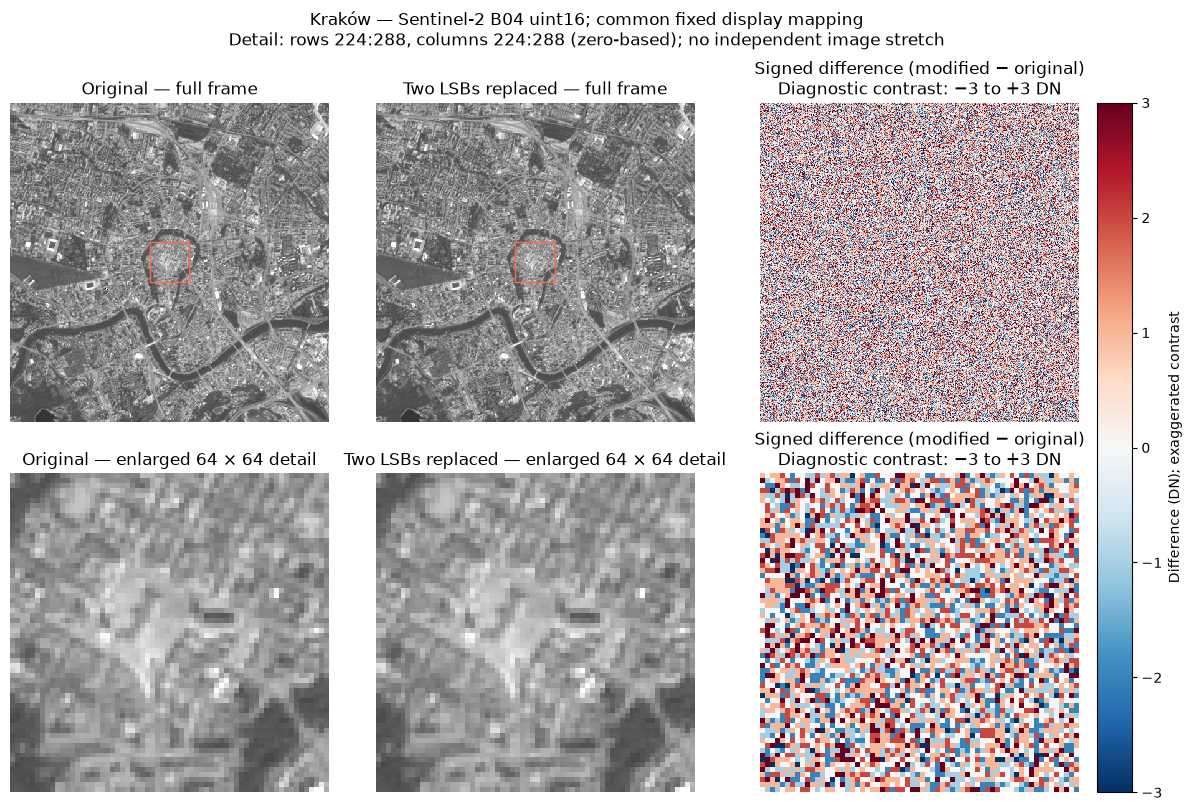

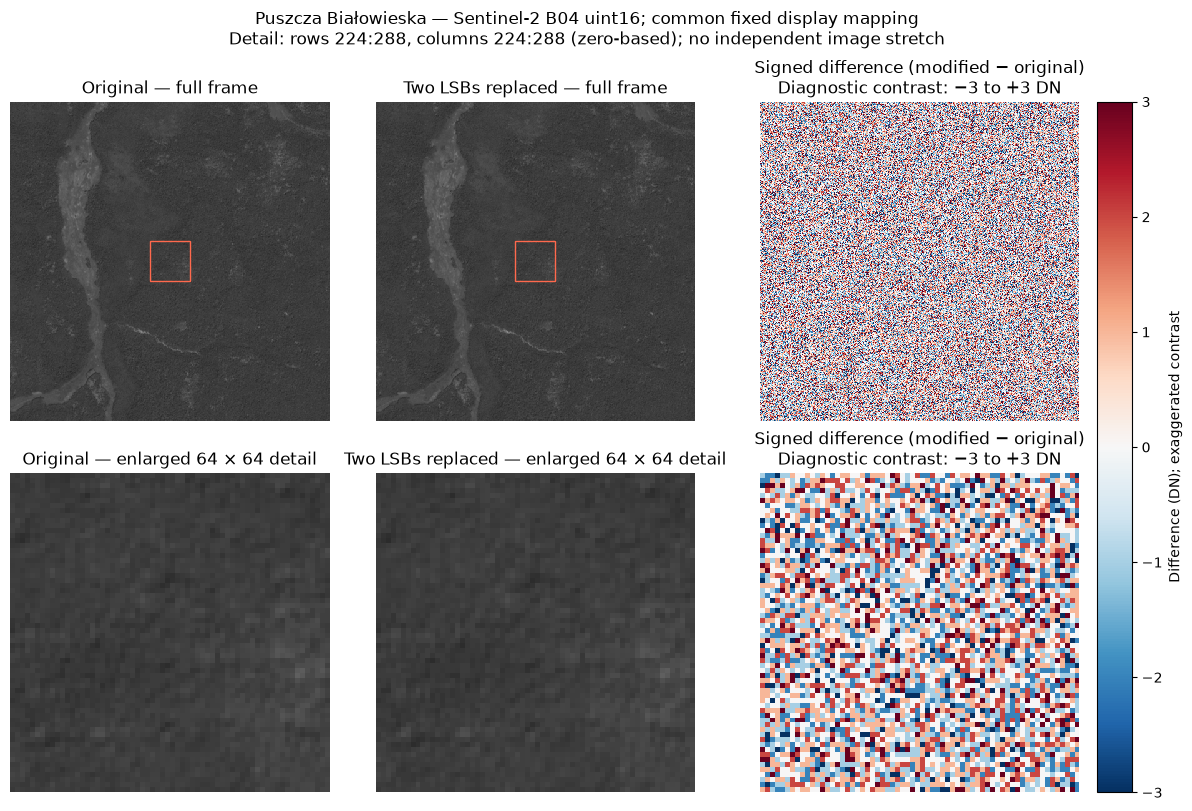

Image mapping: reflectance / 0.3, clip to [0,1], gamma 1/2.2; only diagnostic differences use ±3 DN limits.


In [9]:
from matplotlib.patches import Rectangle

def lsb_display(dn):
    reflectance = dn.astype(np.float64) * 0.0001 - 0.1
    return np.clip(reflectance / 0.3, 0, 1) ** (1 / 2.2)

detail = np.s_[224:288, 224:288]
for region, experiment in lsb_experiments.items():
    original, modified, difference = [experiment[key] for key in ['original', 'modified', 'difference']]
    fig, axes = plt.subplots(2, 3, figsize=(12, 8), constrained_layout=True)
    for col, (label, image) in enumerate([('Original', original), ('Two LSBs replaced', modified)]):
        axes[0, col].imshow(lsb_display(image), cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[0, col].add_patch(Rectangle((223.5, 223.5), 64, 64, fill=False, edgecolor='#ff694d', linewidth=1))
        axes[0, col].set_title(label + ' — full frame')
        axes[1, col].imshow(lsb_display(image[detail]), cmap='gray', vmin=0, vmax=1, interpolation='nearest')
        axes[1, col].set_title(label + ' — enlarged 64 × 64 detail')
    for row, error in enumerate([difference, difference[detail]]):
        diagnostic = axes[row, 2].imshow(error, cmap='RdBu_r', vmin=-3, vmax=3, interpolation='nearest')
        axes[row, 2].set_title('Signed difference (modified − original)' + chr(10) + 'Diagnostic contrast: −3 to +3 DN')
    for ax in axes.flat:
        ax.set_axis_off()
    fig.colorbar(diagnostic, ax=axes[:, 2].tolist(), ticks=range(-3, 4), label='Difference (DN); exaggerated contrast')
    fig.suptitle(region_names[region] + ' — Sentinel-2 B04 uint16; common fixed display mapping' + chr(10)
                 + 'Detail: rows 224:288, columns 224:288 (zero-based); no independent image stretch')
    fig.savefig(LSB_DIR / (region + '_image_comparison.png'), dpi=150)
    plt.show()
print('Image mapping: reflectance / 0.3, clip to [0,1], gamma 1/2.2; only diagnostic differences use ±3 DN limits.')


### Histogram comparison method

The plots show **probability mass = bin count / N**, with the same fixed original valid mask and N for each original/modified pair. Each complete histogram sums to one within 1e−12. Single-DN bins could also be viewed as histogram density per DN, since their width is one; a 64-DN probability mass would need division by 64 to become density. Do not compare the heights of those two representations as if they had the same bin width.

The left column covers the entire occupied DN range with aligned bins [0,64), [64,128), …, on a **logarithmic x axis**. The two curves coincide exactly: every such bin consists of whole groups of four consecutive values, and those groups cannot change when only the two LSBs change. The code checks both 4-DN and 64-DN group counts, not merely visual overlap.

The middle and right columns use **one-DN bins** over a 64-level window centred near the original median (Kraków: 1664–1727 DN; Białowieża: 1100–1163 DN). These are labelled detail views, not complete distributions renormalized to that window. Every displayed probability still uses full valid N. Axes are shared between original and modified and y limits are shared down each column. The separate low-bit and pixel-error plots are supporting diagnostics, not replacements for the full-value histogram. Complete occupied-range single-DN counts are saved as CSVs, including levels outside the detail view.

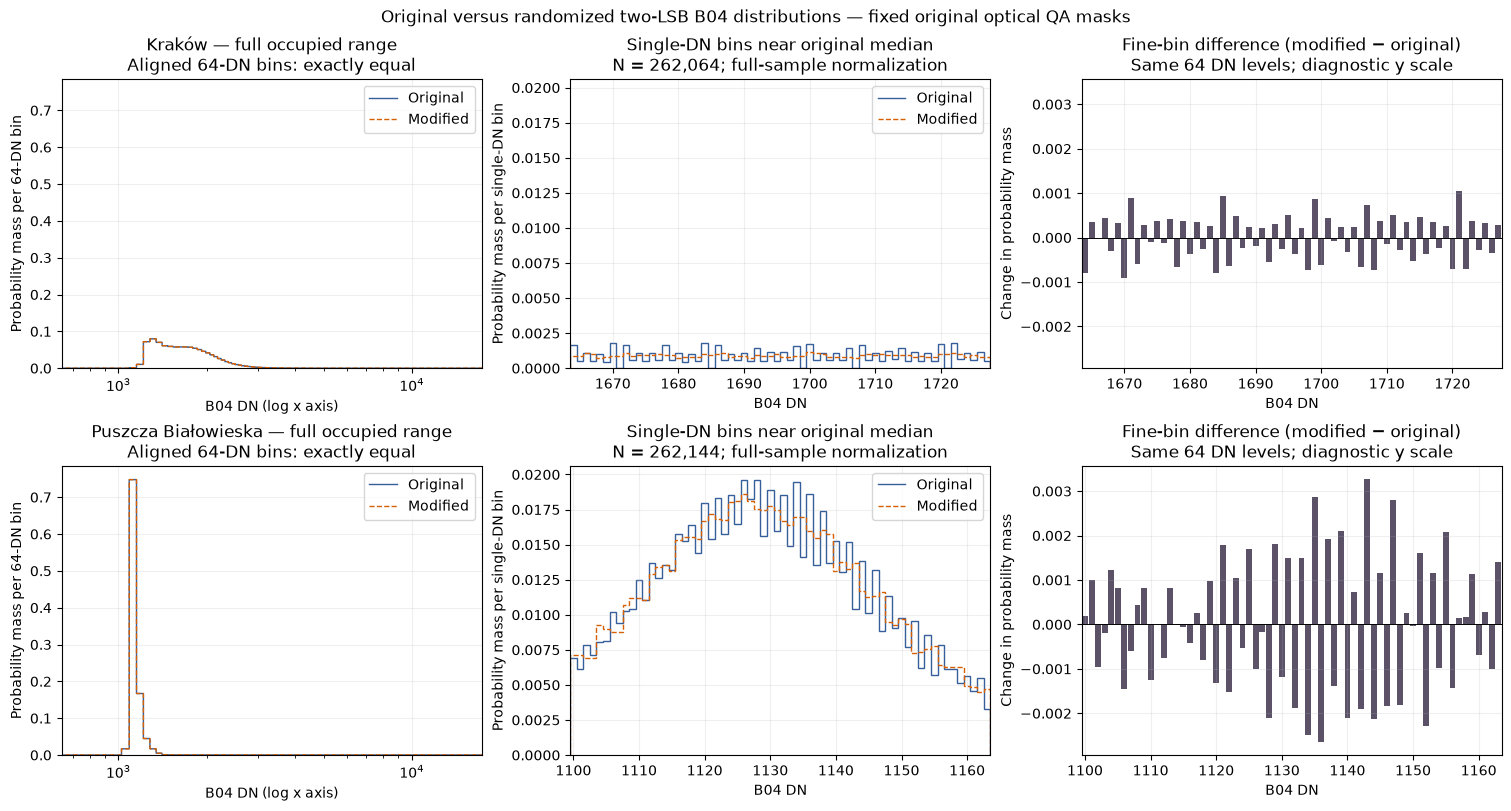

krakow Original two-bit frequencies: [0.38304, 0.11881, 0.38089, 0.11725]
krakow Modified two-bit frequencies: [0.24936, 0.25273, 0.25035, 0.24756]
bialowieza Original two-bit frequencies: [0.27405, 0.22662, 0.27522, 0.22411]
bialowieza Modified two-bit frequencies: [0.24892, 0.24948, 0.25128, 0.25032]


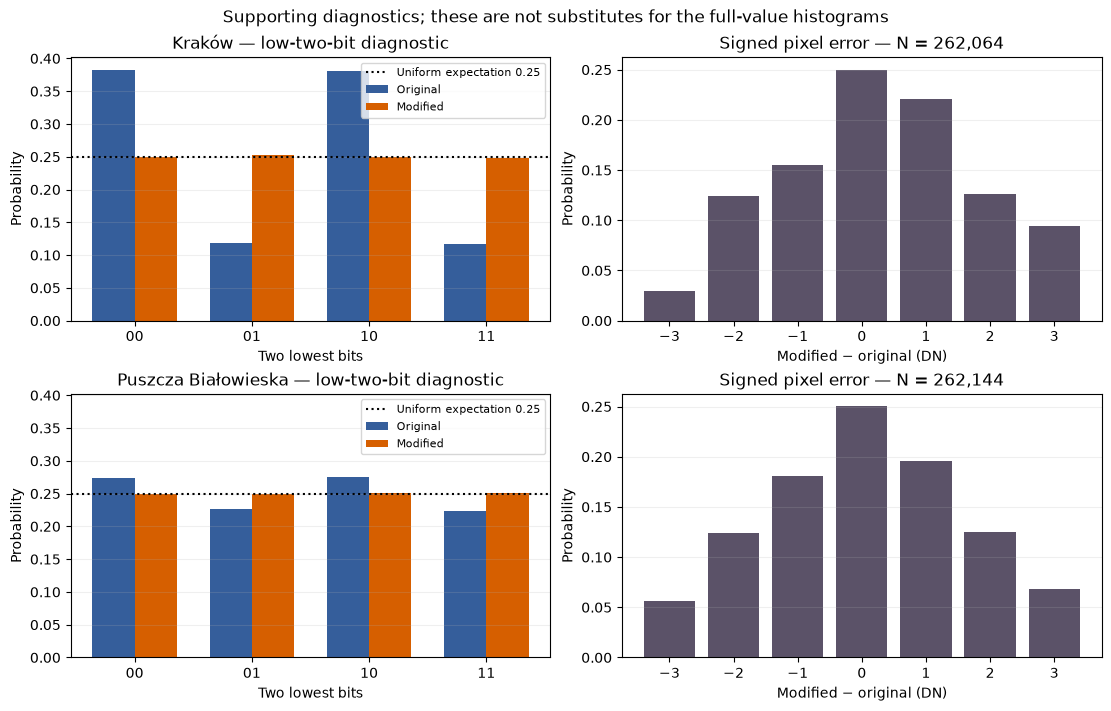

Single-DN histogram differences: {'krakow': {'n': 262064, 'fine_view_dn_start': 1664, 'fine_view_dn_stop_exclusive': 1728, 'single_dn_probability_total_variation': 0.26681268697722693}, 'bialowieza': {'n': 262144, 'fine_view_dn_start': 1100, 'fine_view_dn_stop_exclusive': 1164, 'single_dn_probability_total_variation': 0.0562591552734375}}


In [10]:
ORIGINAL_COLOR, MODIFIED_COLOR = '#355e9b', '#d65f00'
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey='col', constrained_layout=True)
coarse_edges = np.arange(0, 65537, 64)
occupied = np.concatenate([np.flatnonzero(e['hist_original'] + e['hist_modified']) for e in lsb_experiments.values()])
full_limits = (max(1, (occupied.min() // 64) * 64), (occupied.max() // 64 + 1) * 64)
histogram_settings = {}
for row, (region, experiment) in enumerate(lsb_experiments.items()):
    n = int(experiment['valid'].sum())
    h0, h1 = experiment['hist_original'], experiment['hist_modified']
    for counts, label, color, style in [(h0, 'Original', ORIGINAL_COLOR, '-'), (h1, 'Modified', MODIFIED_COLOR, '--')]:
        coarse_mass = counts.reshape(-1, 64).sum(axis=1) / n
        axes[row, 0].stairs(coarse_mass, coarse_edges, label=label, color=color, linestyle=style)
    axes[row, 0].set_xscale('log')
    axes[row, 0].set_xlim(full_limits)
    axes[row, 0].set_title(region_names[region] + ' — full occupied range' + chr(10) + 'Aligned 64-DN bins: exactly equal')
    axes[row, 0].set_xlabel('B04 DN (log x axis)')
    axes[row, 0].set_ylabel('Probability mass per 64-DN bin')
    start = max(0, int(np.median(experiment['original'][experiment['valid']])) // 4 * 4 - 32)
    stop = min(start + 64, 65536)
    dn = np.arange(start, stop)
    unit_edges = np.arange(start - 0.5, stop + 0.5)
    for counts, label, color, style in [(h0, 'Original', ORIGINAL_COLOR, '-'), (h1, 'Modified', MODIFIED_COLOR, '--')]:
        axes[row, 1].stairs(counts[start:stop] / n, unit_edges, label=label, color=color, linestyle=style)
    axes[row, 1].set_title('Single-DN bins near original median' + chr(10) + 'N = ' + format(n, ',') + '; full-sample normalization')
    axes[row, 1].set_xlabel('B04 DN')
    axes[row, 1].set_ylabel('Probability mass per single-DN bin')
    axes[row, 1].set_xlim(start - 0.5, stop - 0.5)
    axes[row, 2].bar(dn, (h1[start:stop] - h0[start:stop]) / n, width=0.9, color='#5b5268')
    axes[row, 2].axhline(0, color='black', linewidth=0.7)
    axes[row, 2].set_title('Fine-bin difference (modified − original)' + chr(10) + 'Same 64 DN levels; diagnostic y scale')
    axes[row, 2].set_xlabel('B04 DN')
    axes[row, 2].set_ylabel('Change in probability mass')
    axes[row, 2].set_xlim(start - 0.5, stop - 0.5)
    for ax in axes[row]:
        ax.grid(alpha=0.2)
    axes[row, 0].legend()
    axes[row, 1].legend()
    histogram_settings[region] = {'n': n, 'fine_view_dn_start': start, 'fine_view_dn_stop_exclusive': stop,
                                  'single_dn_probability_total_variation': float(0.5 * np.abs(h1 - h0).sum() / n)}
fig.suptitle('Original versus randomized two-LSB B04 distributions — fixed original optical QA masks')
fig.savefig(LSB_DIR / 'histogram_comparison.png', dpi=150)
plt.show()
lab_inputs.dump(LSB_DIR / 'histogram_settings.json', {'coarse_bin_width_dn': 64, 'coarse_start_dn': 0,
    'fine_bin_width_dn': 1, 'normalization': 'probability mass = count / full valid N; detail not renormalized',
    'regions': histogram_settings})

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey='col', constrained_layout=True)
diagnostic_rows = []
for row, (region, experiment) in enumerate(lsb_experiments.items()):
    valid = experiment['valid']
    for data, label, color, offset in [(experiment['original'], 'Original', ORIGINAL_COLOR, -0.18),
                                       (experiment['modified'], 'Modified', MODIFIED_COLOR, 0.18)]:
        counts = np.bincount((data[valid] & np.uint16(3)), minlength=4)
        frequencies = counts / int(valid.sum())
        axes[row, 0].bar(np.arange(4) + offset, frequencies, width=0.36, label=label, color=color)
        for low_bits, (count, probability) in enumerate(zip(counts, frequencies)):
            diagnostic_rows.append({'region': region, 'image': label, 'low_two_bits': low_bits,
                                    'count': int(count), 'probability': float(probability)})
        print(region, label, 'two-bit frequencies:', np.round(frequencies, 5).tolist())
    axes[row, 0].axhline(0.25, linestyle=':', color='black', label='Uniform expectation 0.25')
    axes[row, 0].set_xticks(range(4), ['00', '01', '10', '11'])
    axes[row, 0].set_title(region_names[region] + ' — low-two-bit diagnostic')
    axes[row, 0].set_xlabel('Two lowest bits')
    axes[row, 0].set_ylabel('Probability')
    axes[row, 0].legend(fontsize=8)
    error = experiment['difference'][valid]
    error_mass = np.array([np.mean(error == value) for value in range(-3, 4)])
    np.testing.assert_allclose(error_mass.sum(), 1, atol=1e-12, rtol=0)
    axes[row, 1].bar(range(-3, 4), error_mass, color='#5b5268')
    axes[row, 1].set_xticks(range(-3, 4))
    axes[row, 1].set_title('Signed pixel error — N = ' + format(error.size, ','))
    axes[row, 1].set_xlabel('Modified − original (DN)')
    axes[row, 1].set_ylabel('Probability')
    for ax in axes[row]:
        ax.grid(axis='y', alpha=0.2)
fig.suptitle('Supporting diagnostics; these are not substitutes for the full-value histograms')
fig.savefig(LSB_DIR / 'bit_and_error_diagnostics.png', dpi=150)
plt.show()
with (LSB_DIR / 'two_bit_frequencies.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(diagnostic_rows[0]))
    writer.writeheader()
    writer.writerows(diagnostic_rows)
print('Single-DN histogram differences:', histogram_settings)


### Does replacing the two LSBs affect visual quality?

**No clear degradation is visible in the displayed full frames or the enlarged 64 × 64 patches.** Urban edges, the river, and forest texture look preserved under the same reflectance/gamma mapping. This is an informal inspection of these rendered views, not a blinded human-perception study. The images are numerically different: the signed difference maps show widespread changes only because their diagnostic scale spans just −3 to +3 DN. That colour pattern is not the appearance of the modified grayscale image.

| Region (valid pixels) | N | Changed pixels | Changed fraction | MAE (DN) | RMSE (DN) | Maximum error (DN) |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| Kraków | 262,064 | 196,589 | 75.016% | 1.24824 | 1.57875 | 3 |
| Białowieża | 262,144 | 196,574 | 74.987% | 1.24787 | 1.57880 | 3 |

About one quarter of pixels retain their previous two-bit value by chance. Every pixel was assigned a new random two-bit value; unchanged pixels do not mean the operation skipped them. Full-frame metrics are also saved: Kraków has 196,647 changed pixels out of 262,144; Białowieża's full-frame and valid-mask counts coincide.

The maximum 3-DN change is **0.00458% of the uint16 container range** (65535), or **0.0003 reflectance** with the source scale. RMSE is about **0.002409%** of that container range; PSNR using data_range=65535 is **92.36 dB** for both regions. This large PSNR depends on the chosen 16-bit container range and does not itself establish perceptual quality or effective sensor precision. MAE is about **0.000125 reflectance**. Mean signed errors are **+0.26376 DN** in Kraków and **+0.05362 DN** in Białowieża: replacement need not have zero mean when the original low bits are not uniform. Small radiometric changes should not automatically be treated as harmless for every scientific use.

### Do the original and modified histograms differ?

**Yes at single-DN resolution; no for the aligned 64-DN bins used here.** The broad histogram envelope stays unchanged, and the code confirms exactly equal group counts. This equality is guaranteed for bins that contain complete aligned four-level groups. Arbitrary bin boundaries, such as a 50-DN width or a shifted origin, need not give exact equality.

The fine view shows the original adjacent-level variation being redistributed within each group of four. The original low-two-bit probabilities (00, 01, 10, 11) are approximately **38.30%, 11.88%, 38.09%, 11.73%** in Kraków, versus approximately **25% each** after replacement. In Białowieża the original probabilities are **27.41%, 22.66%, 27.52%, 22.41%**, again moving close to 25% each. This measures the original rasters' low-bit pattern; its acquisition/processing cause has not been established here.

Across the complete single-DN histograms, total variation distance, defined as **0.5 × sum(abs(p_modified − p_original))**, is **0.26681** for Kraków and **0.05626** for Białowieża. These quantify redistribution of histogram mass and are not the fractions of changed pixels. Both paired histograms sum to one. The image comparison and the distribution comparison therefore give different information: an unobtrusive image change can substantially alter fine-level value frequencies.

### Can this be used to detect satellite-image manipulation?

**With a trusted original**, pixel differences establish that these rasters changed. The unchanged upper bits, bounded errors and low-bit changes are consistent with this particular controlled operation. Fine histograms expose the changed distribution; a coarse histogram alone would have missed it entirely.

**With only a suspect image**, nearly uniform LSB frequencies or a smoother sequence of four neighbouring counts are at most clues requiring a sensor- and processing-specific reference model. The two original crops already have different low-bit statistics. Quantization, resampling, noise and other legitimate processing can change these statistics, and an originally near-uniform low-bit distribution may show little histogram evidence after random replacement. Other manipulations can preserve histograms exactly, for example by rearranging pixel locations.

Thus these results demonstrate visibility of this experiment in fine histograms, not a validated general-purpose tampering detector. A histogram difference does not by itself identify malicious intent or prove an LSB operation; an unchanged histogram or visually unchanged image does not establish authenticity. Detecting unknown images would require independent authentic/altered examples, realistic processing controls and measured false-positive/false-negative rates; none are claimed here.

### Saved outputs and verification

[results/lsb/](results/lsb/) contains both image-comparison figures, histogram and bit/error diagnostic figures, metrics, seeds/configuration, output hashes, per-level counts and separate original/modified **lossless uint16 GeoTIFFs**. The source lab 1 files are unchanged. Checks passed for shape, dtype, upper/lower bits, ≤3-DN errors, lossless readback, georeferencing, complete histogram counts, probability normalization and invariant four-level/coarse-bin totals. Re-running this notebook regenerates the experiment from the recorded seeds.

## 4. Compressive sensing — question 3 (optional, attempted)

This section **runs the supplied compressive-sensing code from `Basic_opt.ipynb`** (signal generation, sparse sampling, and all three optimization formulations) inside this notebook's kernel. The original tutorial is retained unchanged. Copied computations retain N=500, 50 random samples, the DCT/IDCT, initial guesses, objectives, constraints and SciPy solver defaults. Changes for reproducibility/reporting are: a fixed seed, saved results, warnings/termination diagnostics, and consolidated labelled figures. The unused `skopt` import and notebook `pip install` are omitted. **SciPy is now a direct project dependency**; no scikit-optimize dependency is needed.

The signal is the supplied sum of two sine waves with periods 10 and 200 sample steps. The sampled values and their indices are both known. Zeros at unobserved locations in `xp` are placeholders, not measurements of zero. We assess the supplied methods against the zero-filled baseline on the **same fixed 50 indices**.

Before interpreting any reconstruction, record optimizer success/message, measurement L2 residual, full relative L2 error and RMSE on the **450 unobserved samples**. Low measurement error alone is insufficient. For the later corrected linear program, require successful termination and maximum measurement residual ≤1e−7; report reconstruction error separately without assuming exact recovery. This is a toy-signal exercise, not a compressed acquisition or reconstruction of the Sentinel crops.

In [11]:
import csv
import warnings
from time import perf_counter
import scipy
from scipy import optimize, fftpack
from IPython.display import HTML, display

CS_DIR = ROOT / 'lab2/results/compressive_sensing'
CS_DIR.mkdir(parents=True, exist_ok=True)
CS_SEED = 20261109
np.random.seed(CS_SEED)
# Supplied signal and sampling code (Basic_opt cells 13 and 15).
n = np.linspace(1, 500, 500)
xx = np.sin(2 * np.pi * n / 10) + np.sin(2 * np.pi * n / 200)
N = len(xx)
n = 50
sp = np.array([1] * n + [0] * (N - n))
np.random.shuffle(sp)
xp = xx * sp
observed = sp.astype(bool)
true_dct = fftpack.dct(xx, norm='ortho')
np.testing.assert_allclose(fftpack.idct(true_dct, norm='ortho'), xx, atol=1e-12)
assert observed.sum() == 50 and (~observed).sum() == 450
energy_order = np.sort(true_dct ** 2)[::-1]
energy_fraction = np.cumsum(energy_order) / energy_order.sum()
dct_probe = {'coefficients_abs_gt_1e-6': int(np.count_nonzero(np.abs(true_dct) > 1e-6)),
             'top_two_energy_fraction': float(energy_fraction[1]),
             'coefficients_for_99pct_energy': int(np.searchsorted(energy_fraction, 0.99) + 1)}
cs_results, cs_records, cs_reconstructed = {}, [], {}

def record_cs(name, result=None, elapsed=0.0, warning_messages=(), reconstruction=None):
    signal = fftpack.idct(result.x, norm='ortho') if reconstruction is None else reconstruction
    coefficients = fftpack.dct(signal, norm='ortho') if result is None else result.x
    error = signal - xx
    row = {
        'method': name, 'solver_success': None if result is None else bool(result.success),
        'status': None if result is None else int(result.status),
        'message': 'No solver: baseline' if result is None else str(result.message),
        'iterations': None if result is None else int(result.nit),
        'evaluations': None if result is None else int(getattr(result, 'nfev', 0)),
        'runtime_seconds': float(elapsed),
        'observed_residual_l2': float(np.linalg.norm(error[observed])),
        'observed_max_abs_error': float(np.max(np.abs(error[observed]))),
        'full_relative_l2_error': float(np.linalg.norm(error) / np.linalg.norm(xx)),
        'unobserved_rmse': float(np.sqrt(np.mean(error[~observed] ** 2))),
        'coefficient_l1': float(np.abs(coefficients).sum()),
        'coefficient_l0_exact': int(np.count_nonzero(coefficients)),
        'coefficients_abs_gt_1e-6': int(np.count_nonzero(np.abs(coefficients) > 1e-6)),
        'warnings': list(warning_messages),
    }
    cs_records.append(row)
    cs_reconstructed[name] = signal.copy()
    if result is not None:
        cs_results[name] = result
    print(name, '| success:', row['solver_success'], '|', row['message'], flush=True)
    print('  observed L2:', format(row['observed_residual_l2'], '.5g'),
          '| full relative L2:', format(row['full_relative_l2_error'], '.5g'),
          '| unobserved RMSE:', format(row['unobserved_rmse'], '.5g'), flush=True)
    return row

record_cs('zero_filled', reconstruction=xp)
print('SciPy:', scipy.__version__, '| seed:', CS_SEED, '| samples:', int(observed.sum()), '/', N)
print('Actual DCT sparsity/energy:', dct_probe)


zero_filled | success: None | No solver: baseline
  observed L2: 0 | full relative L2: 0.96011 | unobserved RMSE: 1.012
SciPy: 1.18.1 | seed: 20261109 | samples: 50 / 500
Actual DCT sparsity/energy: {'coefficients_abs_gt_1e-6': 500, 'top_two_energy_fraction': 0.4353869089199434, 'coefficients_for_99pct_energy': 30}


In [12]:
# Supplied measurement-error-only formulation (Basic_opt cell 17).
XX = np.random.rand(N)
def cost_cs(XX):
    xd = fftpack.idct(XX, norm='ortho')
    xdn = xd * sp
    return np.linalg.norm(xdn - xp, ord=2)

seed = np.zeros(N)
started = perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    CS = optimize.minimize(cost_cs, seed, options={'disp': True})
record_cs('supplied_L2_only', CS, perf_counter() - started, [str(w.message) for w in caught])


         Current function value: 0.000001
         Iterations: 3
         Function evaluations: 33078
         Gradient evaluations: 66
supplied_L2_only | success: False | Desired error not necessarily achieved due to precision loss.
  observed L2: 5.2286e-07 | full relative L2: 0.96011 | unobserved RMSE: 1.012


{'method': 'supplied_L2_only',
 'solver_success': False,
 'status': 2,
 'message': 'Desired error not necessarily achieved due to precision loss.',
 'iterations': 3,
 'evaluations': 33078,
 'runtime_seconds': 0.21624450001399964,
 'observed_residual_l2': 5.22863196072159e-07,
 'observed_max_abs_error': 1.691829329963923e-07,
 'full_relative_l2_error': 0.9601052978364114,
 'unobserved_rmse': 1.012039844919131,
 'coefficient_l1': 110.37253311741415,
 'coefficient_l0_exact': 500,
 'coefficients_abs_gt_1e-6': 500,
 'warnings': ['Desired error not necessarily achieved due to precision loss.']}

In [13]:
# Supplied L0-constrained formulation (Basic_opt cell 19).
XX = np.random.rand(N)
def cost_cs(XX):
    xd = fftpack.idct(XX, norm='ortho')
    xdn = xd * sp
    return np.linalg.norm(xdn - xp, ord=2)

cons = {'type': 'ineq', 'fun': lambda XX: n - np.linalg.norm(XX, ord=0)}
seed = np.zeros(N)
started = perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})
record_cs('supplied_L0_constraint', CS, perf_counter() - started, [str(w.message) for w in caught])
print('Exact L0 constraint slack (must be >=0):', n - np.linalg.norm(CS.x, ord=0))


Iteration limit reached    (Exit mode 9)
            Current function value: 1.3944427425974238e-05
            Iterations: 100
            Function evaluations: 51377
            Gradient evaluations: 101
supplied_L0_constraint | success: False | Iteration limit reached
  observed L2: 1.3944e-05 | full relative L2: 0.96033 | unobserved RMSE: 1.0123
Exact L0 constraint slack (must be >=0): -450.0


In [14]:
# Supplied L1 minimization with scalar norm equality (Basic_opt cell 21).
XX = np.random.rand(N)
def cost_cs(XX):
    return np.linalg.norm(XX, ord=1)

cons = {'type': 'eq', 'fun': lambda XX: np.linalg.norm(xp - fftpack.idct(XX, norm='ortho') * sp, ord=2)}
seed = np.random.rand(N)
started = perf_counter()
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    CS = optimize.minimize(cost_cs, seed, constraints=cons, options={'disp': True})
record_cs('supplied_L1_norm_equality', CS, perf_counter() - started, [str(w.message) for w in caught])


Iteration limit reached    (Exit mode 9)
            Current function value: 57.963881275354765
            Iterations: 100
            Function evaluations: 50911
            Gradient evaluations: 101
supplied_L1_norm_equality | success: False | Iteration limit reached
  observed L2: 0.88812 | full relative L2: 0.81679 | unobserved RMSE: 0.85996


{'method': 'supplied_L1_norm_equality',
 'solver_success': False,
 'status': 9,
 'message': 'Iteration limit reached',
 'iterations': 100,
 'evaluations': 50911,
 'runtime_seconds': 0.7321807499974966,
 'observed_residual_l2': 0.8881224727363877,
 'observed_max_abs_error': 0.3319542587591324,
 'full_relative_l2_error': 0.8167930239132575,
 'unobserved_rmse': 0.8599569245415113,
 'coefficient_l1': 57.963881275354765,
 'coefficient_l0_exact': 500,
 'coefficients_abs_gt_1e-6': 500,
 'warnings': []}

### Corrected comparison: basis pursuit on the same measurements

The supplied scalar norm equality is mathematically equivalent to matching every observed sample, but its derivative is problematic at zero residual. The L0 count is discontinuous and unsuitable for the supplied smooth constrained solver. Rather than only increasing iteration limits, solve **minimize ||c||1 subject to A c = y**, where A contains the 50 measured rows of the orthonormal IDCT synthesis matrix and y contains only the measured values.

Write c = u − v with u,v ≥ 0, and minimize sum(u + v) subject to [A,−A][u;v]=y. This is a linear program handled by SciPy's [HiGHS interface](https://docs.scipy.org/doc/scipy/reference/optimize.linprog-highs.html). This change keeps the supplied signal, basis, measurement indices and sample count fixed; it changes the optimizer/formulation, not the available information. L1 promotes sparse coefficients; it is not chosen merely to avoid the square in an L2 error.

A **separate positive control** uses a signal constructed with exactly two nonzero DCT coefficients, measured at the same 50 positions. It tests the sparse-model premise and is labelled separately; it does not replace the supplied sine signal or demonstrate satellite-image recovery.

In [15]:
# IDCT applied down columns maps each unit coefficient vector to its synthesis atom.
idct_basis = fftpack.idct(np.eye(N), axis=0, norm='ortho')
np.testing.assert_allclose(idct_basis @ true_dct, xx, atol=1e-12)
A = idct_basis[observed]
y_observed = xx[observed]
assert A.shape == (50, 500) and np.linalg.matrix_rank(A) == 50

def basis_pursuit(measurements):
    started = perf_counter()
    lp = optimize.linprog(np.ones(2 * N), A_eq=np.hstack([A, -A]),
                          b_eq=measurements, bounds=(0, None), method='highs')
    if not lp.success:
        raise RuntimeError('Basis pursuit failed: ' + lp.message)
    coefficients = lp.x[:N] - lp.x[N:]
    assert np.max(np.abs(A @ coefficients - measurements)) <= 1e-7
    result = optimize.OptimizeResult(x=coefficients, success=lp.success, status=lp.status,
                                    message=lp.message, nit=lp.nit)
    return result, perf_counter() - started

bp, elapsed = basis_pursuit(y_observed)
record_cs('corrected_basis_pursuit', bp, elapsed)
control_coefficients = np.zeros(N)
control_coefficients[[12, 74]] = [12.0, -7.0]
control_signal = idct_basis @ control_coefficients
control_result, control_seconds = basis_pursuit(control_signal[observed])
control_reconstructed = idct_basis @ control_result.x
control_error = control_reconstructed - control_signal
control_metrics = {
    'target': 'separate exactly 2-sparse DCT control', 'nonzero_coefficient_indices': [12, 74],
    'nonzero_coefficient_values': [12.0, -7.0], 'solver_success': bool(control_result.success),
    'message': str(control_result.message), 'iterations': int(control_result.nit),
    'runtime_seconds': control_seconds, 'observed_max_abs_error': float(np.max(np.abs(control_error[observed]))),
    'full_relative_l2_error': float(np.linalg.norm(control_error) / np.linalg.norm(control_signal)),
    'unobserved_rmse': float(np.sqrt(np.mean(control_error[~observed] ** 2))),
    'coefficients_abs_gt_1e-6': int(np.count_nonzero(np.abs(control_result.x) > 1e-6)),
}
print('Separate sparse-model control:', control_metrics)
assert control_metrics['full_relative_l2_error'] < 1e-7, 'Positive-control recovery did not meet the stated numerical criterion'


corrected_basis_pursuit | success: True | Optimization terminated successfully. (HiGHS Status 7: Optimal)
  observed L2: 1.3262e-13 | full relative L2: 0.66601 | unobserved RMSE: 0.70203
Separate sparse-model control: {'target': 'separate exactly 2-sparse DCT control', 'nonzero_coefficient_indices': [12, 74], 'nonzero_coefficient_values': [12.0, -7.0], 'solver_success': True, 'message': 'Optimization terminated successfully. (HiGHS Status 7: Optimal)', 'iterations': 24, 'runtime_seconds': 0.009583791019394994, 'observed_max_abs_error': 3.3306690738754696e-16, 'full_relative_l2_error': 3.0347302082583144e-16, 'unobserved_rmse': 1.894005943400725e-16, 'coefficients_abs_gt_1e-6': 2}


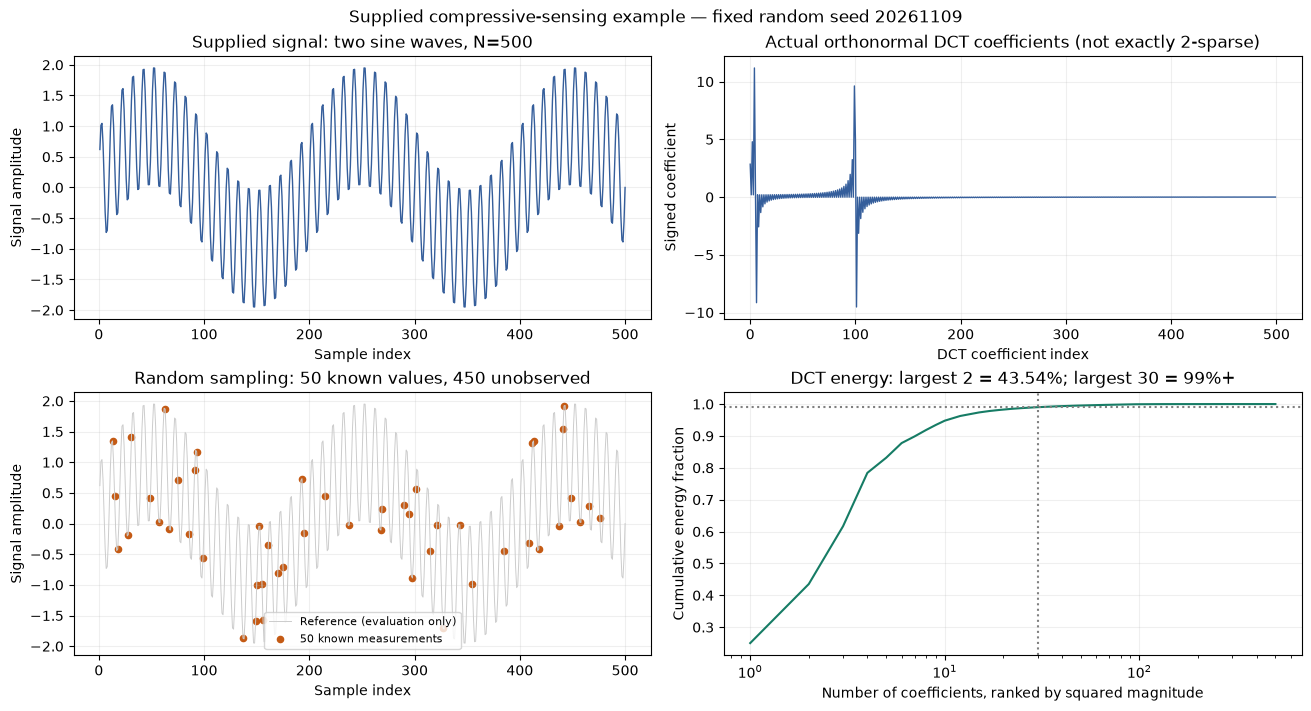

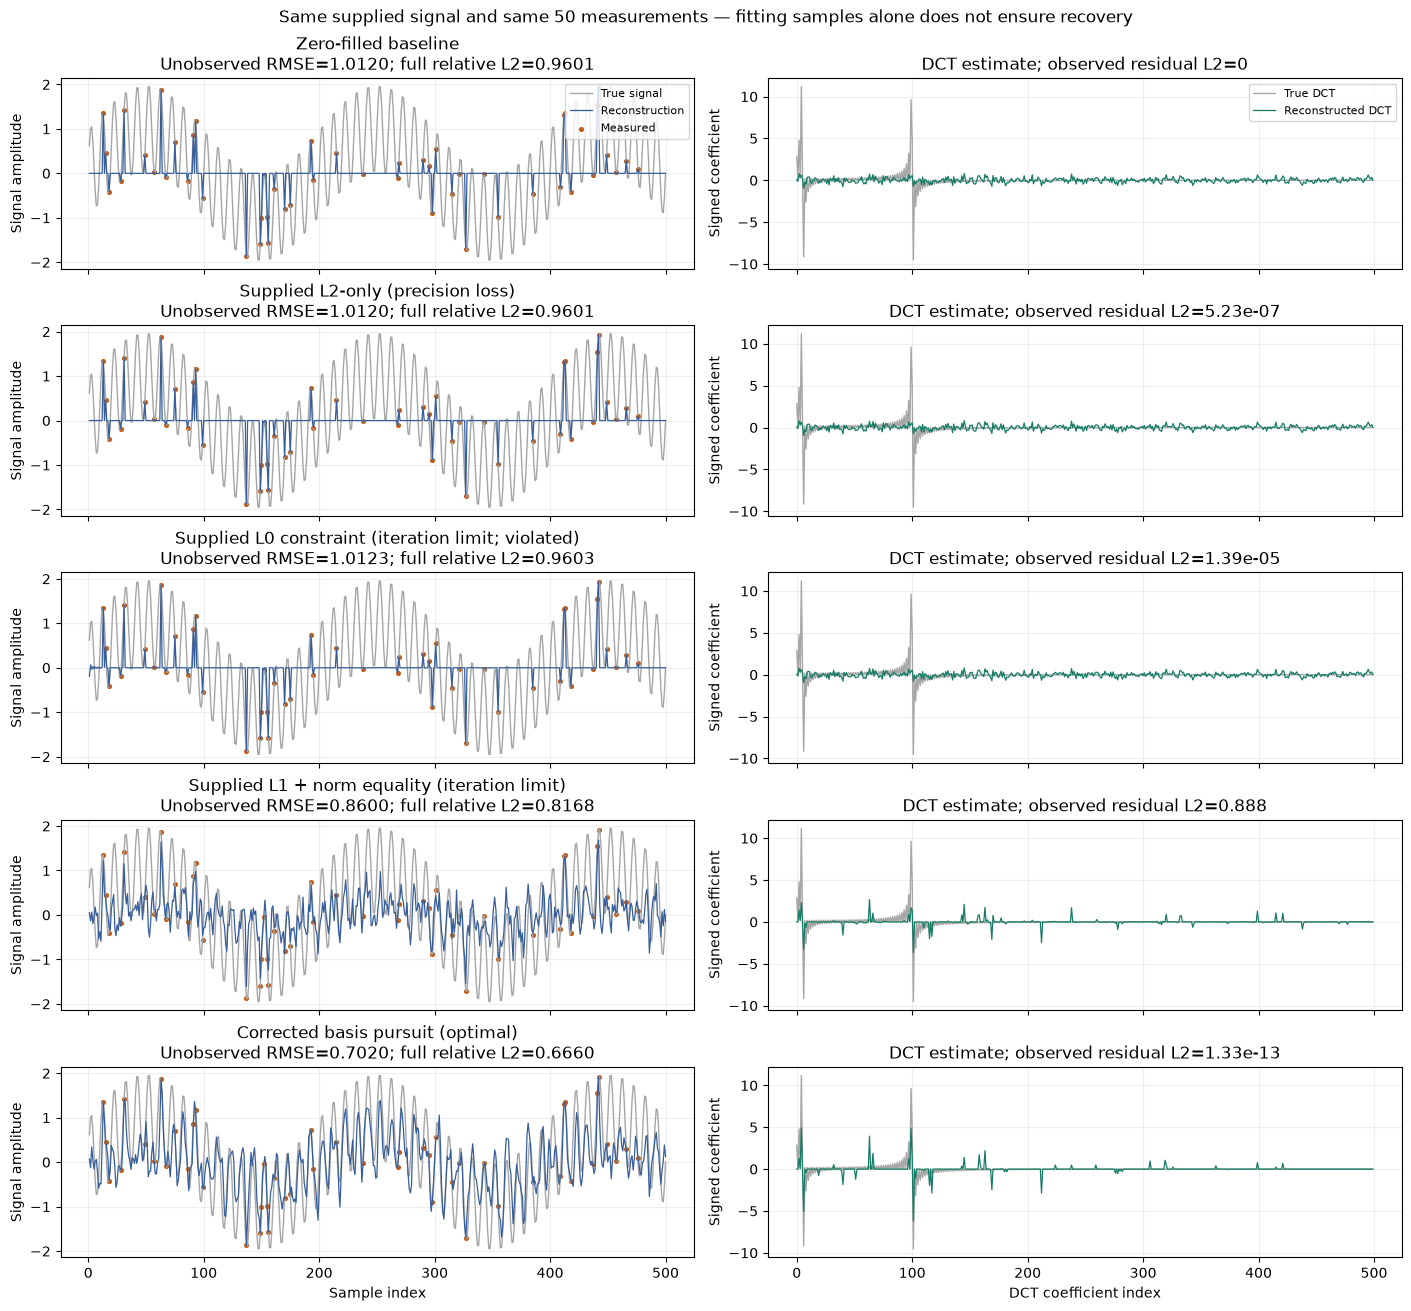

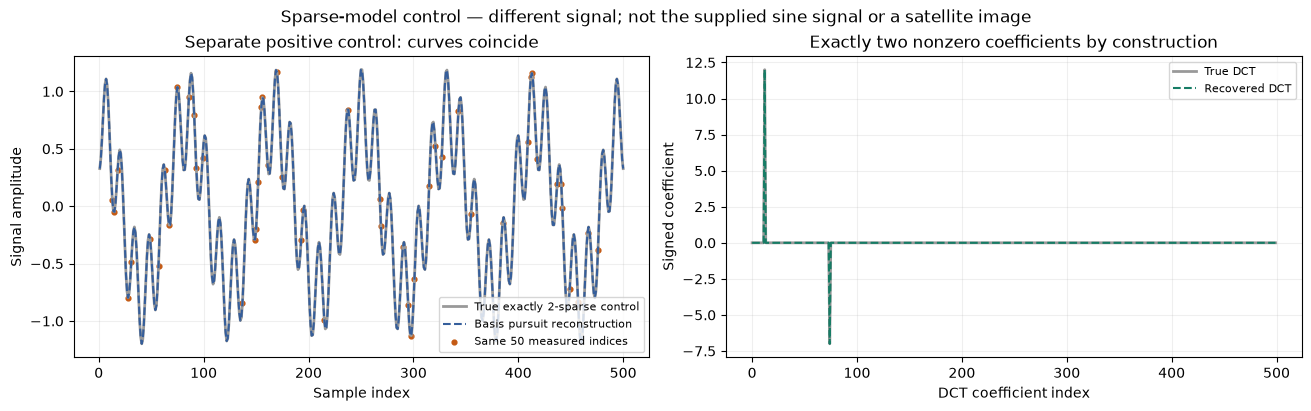

method,solver_success,iterations,observed_residual_l2,full_relative_l2_error,unobserved_rmse,coefficients_abs_gt_1e-6
zero_filled,None,None,0,0.96011,1.012,500
supplied_L2_only,False,3,5.2286e-07,0.96011,1.012,500
supplied_L0_constraint,False,100,1.3944e-05,0.96033,1.0123,500
supplied_L1_norm_equality,False,100,0.88812,0.81679,0.85996,500
corrected_basis_pursuit,True,135,1.3262e-13,0.66601,0.70203,50


Saved all input/measurement, reconstruction, coefficient and control figures plus metrics and arrays.


In [16]:
cs_time = np.arange(1, N + 1)
fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
axes[0, 0].plot(cs_time, xx, linewidth=1, color='#355e9b')
axes[0, 0].set_title('Supplied signal: two sine waves, N=500')
axes[0, 0].set_xlabel('Sample index'); axes[0, 0].set_ylabel('Signal amplitude')
axes[0, 1].plot(np.arange(N), true_dct, linewidth=1, color='#355e9b')
axes[0, 1].set_title('Actual orthonormal DCT coefficients (not exactly 2-sparse)')
axes[0, 1].set_xlabel('DCT coefficient index'); axes[0, 1].set_ylabel('Signed coefficient')
axes[1, 0].plot(cs_time, xx, linewidth=0.7, color='0.8', label='Reference (evaluation only)')
axes[1, 0].scatter(cs_time[observed], xx[observed], s=20, color='#c45a14', label='50 known measurements')
axes[1, 0].set_title('Random sampling: 50 known values, 450 unobserved')
axes[1, 0].set_xlabel('Sample index'); axes[1, 0].set_ylabel('Signal amplitude')
axes[1, 0].legend(fontsize=8)
axes[1, 1].plot(np.arange(1, N + 1), energy_fraction, color='#167c65')
axes[1, 1].axhline(0.99, color='gray', linestyle=':')
axes[1, 1].axvline(dct_probe['coefficients_for_99pct_energy'], color='gray', linestyle=':')
axes[1, 1].set_title('DCT energy: largest 2 = 43.54%; largest 30 = 99%+')
axes[1, 1].set_xlabel('Number of coefficients, ranked by squared magnitude')
axes[1, 1].set_ylabel('Cumulative energy fraction')
axes[1, 1].set_xscale('log')
for ax in axes.flat:
    ax.grid(alpha=0.2)
fig.suptitle('Supplied compressive-sensing example — fixed random seed 20261109')
fig.savefig(CS_DIR / 'signal_sampling_and_dct.png', dpi=150)
plt.show()

method_labels = {'zero_filled': 'Zero-filled baseline', 'supplied_L2_only': 'Supplied L2-only (precision loss)',
                 'supplied_L0_constraint': 'Supplied L0 constraint (iteration limit; violated)',
                 'supplied_L1_norm_equality': 'Supplied L1 + norm equality (iteration limit)',
                 'corrected_basis_pursuit': 'Corrected basis pursuit (optimal)'}
fig, axes = plt.subplots(len(cs_records), 2, figsize=(14, 13), sharex='col', sharey='col', constrained_layout=True)
for row, metrics in enumerate(cs_records):
    name = metrics['method']
    reconstruction = cs_reconstructed[name]
    coefficients = fftpack.dct(reconstruction, norm='ortho')
    axes[row, 0].plot(cs_time, xx, color='0.65', linewidth=1.0, label='True signal')
    axes[row, 0].plot(cs_time, reconstruction, color='#355e9b', linewidth=0.9, label='Reconstruction')
    axes[row, 0].scatter(cs_time[observed], xx[observed], s=7, color='#c45a14', label='Measured')
    axes[row, 0].set_title(method_labels[name] + chr(10) + 'Unobserved RMSE=' + format(metrics['unobserved_rmse'], '.4f')
                           + '; full relative L2=' + format(metrics['full_relative_l2_error'], '.4f'))
    axes[row, 0].set_ylabel('Signal amplitude')
    axes[row, 1].plot(np.arange(N), true_dct, color='0.65', linewidth=1.0, label='True DCT')
    axes[row, 1].plot(np.arange(N), coefficients, color='#167c65', linewidth=0.9, label='Reconstructed DCT')
    axes[row, 1].set_title('DCT estimate; observed residual L2=' + format(metrics['observed_residual_l2'], '.3g'))
    axes[row, 1].set_ylabel('Signed coefficient')
    for ax in axes[row]:
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8, loc='upper right')
axes[0, 1].legend(fontsize=8, loc='upper right')
axes[-1, 0].set_xlabel('Sample index'); axes[-1, 1].set_xlabel('DCT coefficient index')
fig.suptitle('Same supplied signal and same 50 measurements — fitting samples alone does not ensure recovery')
fig.savefig(CS_DIR / 'reconstruction_comparison.png', dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
axes[0].plot(cs_time, control_signal, color='0.6', linewidth=2, label='True exactly 2-sparse control')
axes[0].plot(cs_time, control_reconstructed, color='#355e9b', linestyle='--', label='Basis pursuit reconstruction')
axes[0].scatter(cs_time[observed], control_signal[observed], s=12, color='#c45a14', label='Same 50 measured indices')
axes[0].set_xlabel('Sample index'); axes[0].set_ylabel('Signal amplitude')
axes[0].set_title('Separate positive control: curves coincide')
axes[1].plot(np.arange(N), control_coefficients, color='0.6', linewidth=2, label='True DCT')
axes[1].plot(np.arange(N), control_result.x, color='#167c65', linestyle='--', label='Recovered DCT')
axes[1].set_xlabel('DCT coefficient index'); axes[1].set_ylabel('Signed coefficient')
axes[1].set_title('Exactly two nonzero coefficients by construction')
for ax in axes:
    ax.grid(alpha=0.2); ax.legend(fontsize=8)
fig.suptitle('Sparse-model control — different signal; not the supplied sine signal or a satellite image')
fig.savefig(CS_DIR / 'exact_sparse_control.png', dpi=150)
plt.show()

columns = ['method', 'solver_success', 'iterations', 'observed_residual_l2', 'full_relative_l2_error', 'unobserved_rmse', 'coefficients_abs_gt_1e-6']
header = '<tr>' + ''.join('<th>' + key + '</th>' for key in columns) + '</tr>'
body = ''.join('<tr>' + ''.join('<td>' + (format(row[key], '.5g') if isinstance(row[key], float) else str(row[key])) + '</td>' for key in columns) + '</tr>' for row in cs_records)
display(HTML('<table>' + header + body + '</table>'))
with (CS_DIR / 'metrics.csv').open('w', newline='') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(cs_records[0]))
    writer.writeheader(); writer.writerows(cs_records)
lab_inputs.dump(CS_DIR / 'metrics.json', {'supplied_signal': cs_records, 'separate_exact_sparse_control': control_metrics})
lab_inputs.dump(CS_DIR / 'run_metadata.json', {
    'seed': CS_SEED, 'rng': 'NumPy legacy MT19937, preserving tutorial draw sequence',
    'N': N, 'measured_count': int(observed.sum()), 'unobserved_count': int((~observed).sum()),
    'sample_indices_zero_based': np.flatnonzero(observed).tolist(),
    'signal': 'sin(2*pi*t/10) + sin(2*pi*t/200), t=1..500', 'dct_probe': dct_probe,
    'versions': {'python': platform.python_version(), 'numpy': version('numpy'), 'scipy': scipy.__version__, 'matplotlib': version('matplotlib')},
    'reference': 'Basic_opt.ipynb, zero-based cells 13,15,17,19,21; originals retained',
    'baseline_changes': 'fixed seed; diagnostics and consolidated plots; unused skopt/install omitted; supplied optimizer defaults retained',
    'corrected_method': 'basis pursuit via u-v nonnegative linear program; HiGHS defaults; same A and y',
    'positive_control': 'different signal with DCT indices 12,74 = 12,-7; same A',
    'basis_pursuit_measurement_max_abs_tolerance': 1e-7,
    'positive_control_relative_l2_tolerance': 1e-7,
})
np.savez_compressed(CS_DIR / 'arrays.npz', t=cs_time, signal=xx, mask=sp, true_dct=true_dct,
                    control_signal=control_signal, control_true_dct=control_coefficients,
                    control_reconstruction=control_reconstructed,
                    **{name: array for name, array in cs_reconstructed.items()})
print('Saved all input/measurement, reconstruction, coefficient and control figures plus metrics and arrays.')

### Results and observations

**What happened when the supplied code ran?**

| Method on supplied sine signal | Solver outcome | Observed residual L2 | Full relative L2 error | RMSE on 450 unobserved samples |
| --- | --- | ---: | ---: | ---: |
| Zero-filled baseline | No optimizer | 0 | 0.9601 | 1.0120 |
| Supplied measurement L2 only | Precision loss, success=False | 5.23e−7 | 0.9601 | 1.0120 |
| Supplied L0 constraint | Iteration limit (100), success=False | 1.39e−5 | 0.9603 | 1.0123 |
| Supplied L1 with norm equality | Iteration limit (100), success=False | 0.8881 | 0.8168 | 0.8600 |
| Corrected basis pursuit, same data | Optimal, success=True | 1.33e−13 | 0.6660 | 0.7020 |

The first two supplied reconstructions visually resemble the zero-filled baseline: values are mostly recovered where they were already measured, with little information recovered between them. The L2-only objective does not prefer sparse transform coefficients, so a near-zero measurement residual is compatible with a very poor complete reconstruction. Its precision-loss warning is preserved rather than described as successful convergence.

The L0-constrained run is **infeasible**, not just unfinished: it returns 500 exactly nonzero coefficients against a permitted count of 50, giving constraint slack **−450**. Counting nonzeros is discontinuous, so finite-difference SLSQP is a poor method for enforcing this constraint. The supplied L1 run gives a somewhat better missing-sample RMSE, but does not meet its equality constraint and stops at the default iteration limit. Its L1 objective is about **57.96**, lower than the feasible basis-pursuit value **62.57**; that is not a better feasible optimum because the former has a substantial measurement residual.

The corrected linear program matches the 50 measured samples to numerical precision and improves unobserved RMSE to **0.7020**, but the plot still shows many incorrect amplitudes and oscillations between samples. Its **66.6% full relative L2 error** rules out claiming accurate recovery of this signal. Solver success certifies solving this optimization problem to its tolerances, not identifying the true signal uniquely from insufficiently informative measurements.

**Check the tutorial's sparsity and Nyquist claims.** The supplied sum of two sine waves is not represented by only two nonzero DCT coefficients. All **500** coefficients exceed 1e−6 in magnitude; the largest two contain **43.54%** of the energy, while **30** are needed to exceed 99%. A two-frequency sine model is not automatically two-sparse in the cosine basis with these finite-window phases/boundaries. This basis mismatch/compressibility, the sample count and this particular random mask limit recovery. The separate exactly two-sparse DCT control is recovered to about **3e−16 relative L2 error** from the same 50 indices, showing a successful case when the sparse model really holds; it is a different signal.

The experiment retains **10% of the original 500 samples** and demonstrates conditional recovery under a prior, not a general violation of Nyquist sampling. Arbitrary band-limited signals and signals known to have a sparse representation are different modelling assumptions. No claim of a universal 10:1 recovery rate follows from this one noiseless control. Noisy data would need a noise-aware constraint or penalty rather than demanding exact equality.

### Where could compressive sensing be useful in Earth observation?

**Potential acquisition and downlink savings.** If a scene has a useful sparse or compressible representation and the sensing operator preserves enough information about that representation, coded spatial/spectral measurements could reduce how much an instrument reads or transmits. Hyperspectral imaging is a concrete research example: [Meza et al. (2018)](https://pubmed.ncbi.nlm.nih.gov/29609390/) reconstruct spatial-spectral cubes from optically compressed measurements and describe a laboratory system using a micromirror device and near-infrared spectrometer. Applying such ideas to EO could reduce measurement or data-link demands, but the savings would depend on instrument design, noise and the scientific quality required; this notebook has not measured those savings.

**Sparse reconstruction for EO inverse problems.** The [TUM/DLR SparsEO project](https://www.asg.ed.tum.de/sipeo/projects/sparseo/) describes sparse models for pan-sharpening, hyperspectral/multispectral fusion and hyperspectral unmixing. These are related uses of structured priors: measurements and a forward model constrain an otherwise underdetermined solution. They are not all identical to randomly discarding image pixels. SAR reconstruction would likewise need an acquisition-appropriate radar forward model rather than treating a processed backscatter raster as this one-dimensional signal.

**Assumptions and limitations.** The representation, sampling pattern and forward model must suit the scene; sample indices/coding metadata must be known; and calibration errors, noise, motion and misregistration must be considered. Dense urban texture, forest texture, SAR speckle or rare small targets may not follow a simple sparse model. A regularizer can suppress real weak features or produce plausible but incorrect values. EO validation should therefore assess radiometric/spectral accuracy, spatial detail and the intended downstream task on independent scenes and realistic noise, not just visual similarity or measurement fit.

Generating all 500 values first and retaining 50 is a simulation. It does not itself save instrument acquisition cost, and reducing values after full acquisition is different from designing compressed measurements at the sensor. The lab's Sentinel images have not been subjected to a compressive acquisition/recovery test. The useful lesson from the supplied failures and the successful sparse control is to **check the representation and unmeasured error**, as well as solver convergence, before claiming an EO benefit.

### Reproduction and saved results

Run all cells in order with the project's `.venv` kernel after `uv sync --locked`. SciPy is explicitly listed in `pyproject.toml` and locked in `uv.lock`; the unused `skopt` import/install is unnecessary for these experiments. The source tutorial remains unchanged. The main notebook reproduces its compressive-sensing computations with the fixed seed and separately labels the corrected formulation and positive control.

[results/compressive_sensing/](results/compressive_sensing/) contains **three figure files**, `metrics.csv`, `metrics.json`, `run_metadata.json` and `arrays.npz` (signal, mask, reconstructions, true DCT and separate control). Metadata records versions, measurement indices, initial-random-sequence convention, formulation changes and tolerances. Observations refer to this recorded seed and environment; they are not a multi-seed robustness study.

## 5. Final notebook and submission checks

All assignment questions are mapped to evidence in [SUBMISSION_REVIEW.md](SUBMISSION_REVIEW.md). The following audit verifies the saved inputs/results independently of the in-memory experiment arrays and repeats it on a relocated copy with network calls blocked. It does not rerun or validate the original tutorial's historical outputs. Expected nonconvergence of the supplied CS optimizers remains explicitly reported in section 4.

Scientific figures were reviewed for labels, units, common scales, clipping disclosures and legibility. The overview below is a visual index; use the full saved figures for reading fine details. After a clean Run All, build the portable ZIP using the instructions in the submission review.

{
  "status": "passed",
  "input_hashes": 26,
  "histograms_verified_against_rasters": 14,
  "lsb_regions_verified": 2,
  "cs_methods_verified": 5,
  "figures_decoded": 12,
  "private_credentials_required_for_saved_data": false,
  "relocated_copy_offline": "passed"
}


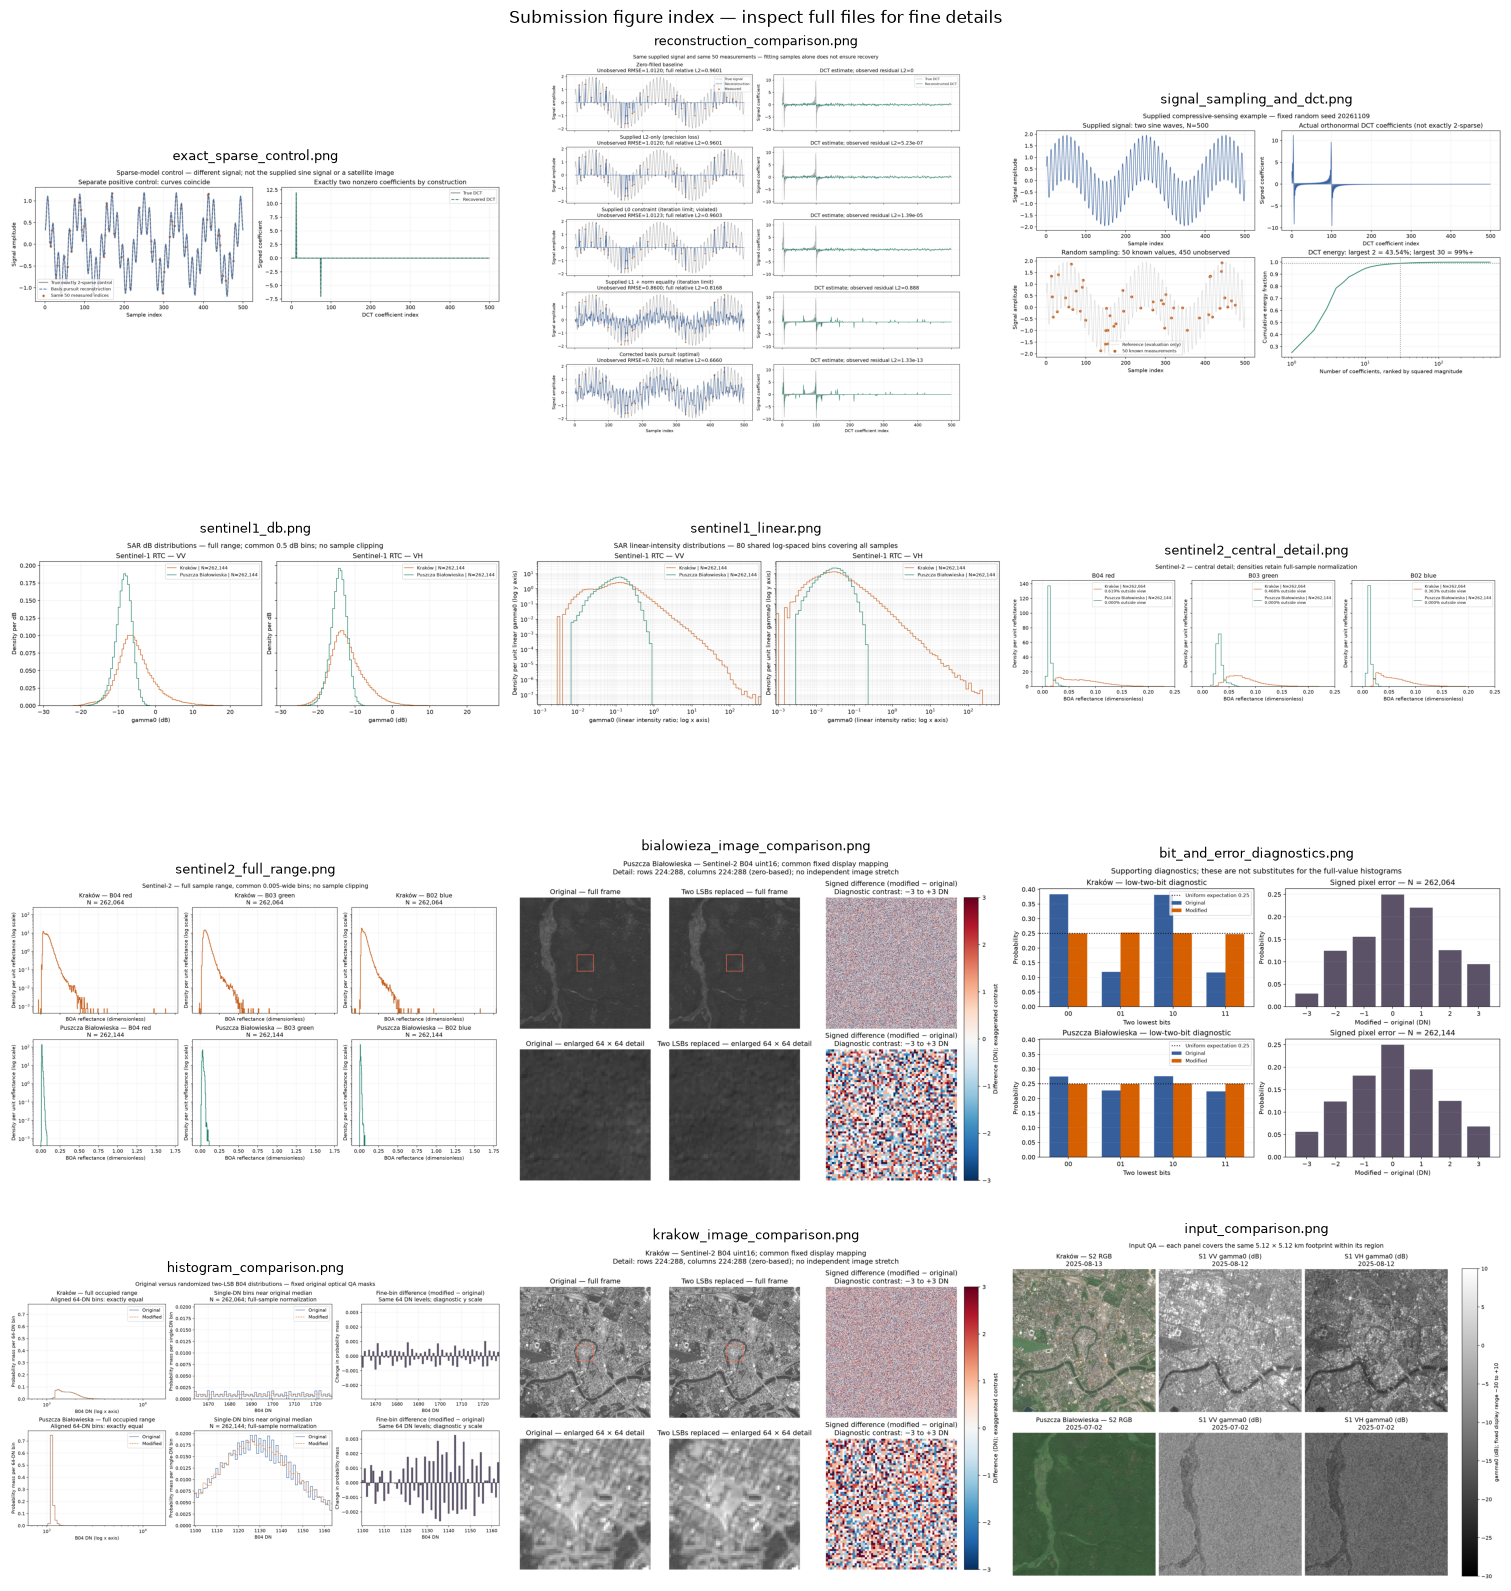

In [17]:
import shutil
import socket
import tempfile
from unittest.mock import patch
import submission as lab_submission

submission_audit = lab_submission.verify_artifacts(ROOT)
# Check relative paths and bundled dependencies in an isolated directory.
# Network denial applies only to this check, not the kernel's normal communication.
with tempfile.TemporaryDirectory(prefix='mlforspace-lab2-check-') as temporary:
    relocated_root = (Path(temporary) / 'MLForSpace-lab2').resolve()
    for path in lab_submission.submission_files(ROOT):
        destination = relocated_root / path.relative_to(ROOT)
        destination.parent.mkdir(parents=True, exist_ok=True)
        shutil.copyfile(path, destination)
    # Import the input helper from the relocated copy under a separate module name.
    import importlib.util
    spec = importlib.util.spec_from_file_location('relocated_lab2_inputs', relocated_root / 'lab2/inputs.py')
    relocated_inputs = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(relocated_inputs)
    with patch.object(socket, 'create_connection', side_effect=AssertionError('Network is disabled during offline verification')):
        relocated_manifest, relocated_data = relocated_inputs.load_inputs()
        relocated_audit = lab_submission.verify_artifacts(relocated_root)
    assert relocated_inputs.ROOT == relocated_root, 'Relocated input helper did not resolve the copied repository'
    assert relocated_manifest['sha256'] == manifest['sha256']
    assert set(relocated_data) == {'krakow', 'bialowieza'}
    assert relocated_audit == submission_audit, 'Relocated artifact checks differ from the original'
submission_audit['relocated_copy_offline'] = 'passed'
lab_inputs.dump(ROOT / 'lab2/results/submission_checks.json', submission_audit)
print(json.dumps(submission_audit, indent=2))

figure_paths = sorted((ROOT / 'lab2/results').rglob('*.png')) + [ROOT / 'lab2/data/input_comparison.png']
fig, axes = plt.subplots(4, 3, figsize=(15, 16), constrained_layout=True)
for ax, path in zip(axes.flat, figure_paths):
    with Image.open(path) as image:
        ax.imshow(np.asarray(image))
    ax.set_title(path.name, fontsize=9)
    ax.set_axis_off()
fig.suptitle('Submission figure index — inspect full files for fine details')
plt.show()